# Profiling de SLMs: descobrir onde o tempo vai

### Capítulo 10 de *Domain-Specific Small Language Models* (Iozzia), aplicado a um gerador de Python

Este notebook acompanha o guia [`wiki.md`](https://github.com/luizpaulobarroca/IAG-2026-SLM/blob/docs/slm-profiling-wiki-20261125/content/small-language-model/practice/profiling/overview.md). Com um experimento em CPU, ele sai de uma sensação vaga ("o modelo está lento") para decisões sustentadas por medição, perfil de operadores, Lei de Amdahl e conferência da saída.

**Objetivos:** distinguir cronômetro de profiler; separar *prefill*, *decode* e cache KV; ler eventos JSON do ONNX Runtime com unidades e denominadores corretos; diferenciar otimização de grafo de quantização dinâmica INT8; reconhecer o que uma avaliação pequena prova e o que não prova; formular hipóteses testáveis ligando perfil, tráfego de memória, hardware e decisões multiobjetivo (fronteira de Pareto).

**Pré-requisitos:** Python básico (funções e `pandas`), noção de multiplicação de matrizes e familiaridade inicial com Transformers.

**Profiling** é medir *por dentro* de um programa: em vez de um único número para a execução inteira, registrar quanto tempo cada parte levou. O cronômetro responde *"está lento?"*; o profiler responde *"o que está lento?"*, e é essa segunda resposta que indica onde vale a pena otimizar.

| | Cronômetro | Profiler do ONNX Runtime |
|---|---|---|
| Mede | a chamada inteira | cada operação (*kernel*) do grafo |
| Responde | quanto demorou | **onde** o tempo foi gasto |
| Custo | quase nenhum | registra milhares de eventos; vem **desligado por padrão** |

O percurso segue um ciclo: medir → diagnosticar → modificar → validar.

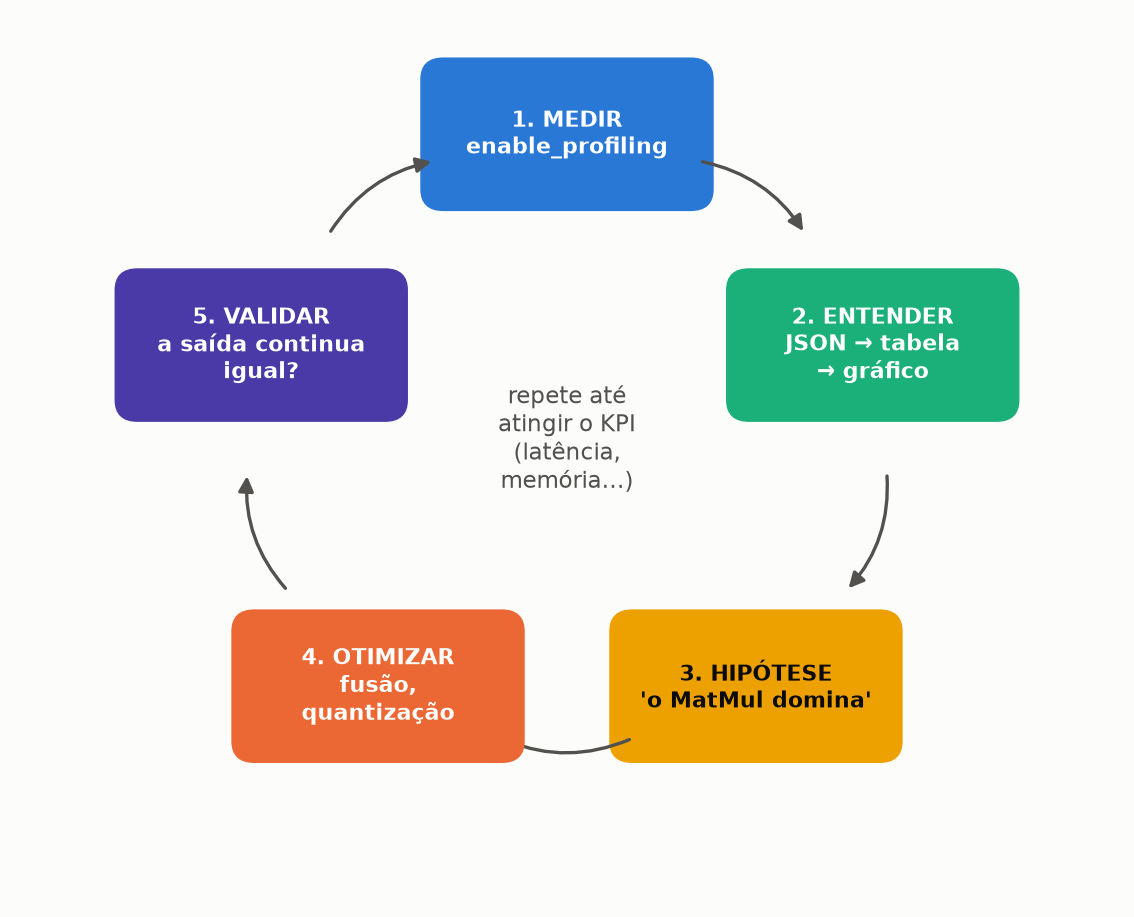

**Modelo:** [Qwen2.5-Coder-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-Coder-0.5B-Instruct) (~494 milhões de parâmetros, 24 camadas), exportado para ONNX e executado pelo ONNX Runtime na CPU.

**Percurso principal:** 0 (exemplo mínimo) → 1 (o caso) → 2 (prefill e exportação) → 3–4 (profiler e gargalo) → 5 (otimização de grafo) → 6 (INT8) → 7 (a resposta continua correta?) → 8 (fechamento) → além do livro → exercícios. Aprofundamentos ficam em blocos recolhidos (▸) e nos apêndices.

> **De onde vêm os números do texto.** As medições identificadas como **25/11/2026** vêm da execução Linux local; os exemplos de Pareto são hipotéticos. Os demais resultados experimentais são o **registro histórico de 20/10/2026**: MacBook Apple M4, CPU, duas threads, Python 3.11.17, torch 2.5.1, transformers 4.46.3, ONNX Runtime 1.20.1, máquina não isolada, medidos em um grafo exportado com **formas fixas**. Esta versão consolidada é distribuída **sem saídas de código** e exporta o prefill **uma única vez com eixo de sequência dinâmico (`dynamic_axes`)**, o que pode alterar contagens de nós, fusões e latências; por isso, não trate os dois ensaios como equivalentes. Em 25/11/2026, as 14 células do percurso principal rodaram com o Qwen real em contêiner Linux local (distinto de execução no Google Colab), com checkpoint em `SLMs_Python_Profiling_validacao_parcial.ipynb` e resumo em `RELATORIO_TECNICO.md`; o notebook incluindo o apêndice opcional FP16 segue incompleto por falta de memória sob 6,5 GiB. Compare variantes apenas dentro da mesma medição pareada.

### Como executar este notebook

1. **Ambiente:** CPU basta; nenhum passo usa GPU. Execute as células **na ordem**, sem pular.
2. **Dependências:** a primeira célula instala as versões do registro. Se o NumPy instalado mudar, o Colab pede para reiniciar a sessão; reinicie e continue da célula seguinte. A célula de configuração para com uma mensagem se o NumPy carregado não for o instalado e lista as versões diferentes das do registro. O `torch` não é reinstalado: usa-se o do ambiente, e a exportação seleciona explicitamente o exportador TorchScript (`dynamo=False`), porque a partir do PyTorch 2.9 o padrão passou a ser outro exportador.
3. **Recursos:** o download do modelo tem ~1 GB. Os arquivos ONNX somam ~3,5 GB (um FP32 dinâmico de ~2,5 GB e um INT8 de ~1 GB; o grafo otimizado reaproveita os pesos do FP32 na mesma pasta) e mais ~1,3 GB com o apêndice A. O prefill é exportado uma única vez (já com sequência dinâmica) e quantizado uma única vez, sendo reutilizado na seção 7 sem recarregar o PyTorch. Cada seção libera o modelo e as sessões que não usa mais; mesmo assim, a quantização e a comparação FP32 × INT8 pedem alguns GB de RAM. Os limites e o pico de memória observados na execução local ficam em `evidencias/execucao_20261125/` e `RELATORIO_TECNICO.md`. **Esta versão não foi executada no Colab**; uma tentativa anterior no Colab gratuito, com outro modelo, esgotou a RAM na quantização.
4. As três células seguintes preparam o ambiente e vêm recolhidas. O apêndice A (FP16) é opcional; o apêndice B guarda as saídas de 20/10/2026.

In [ ]:
# @title Dependências (se o NumPy mudar de versão, reinicie a sessão antes de continuar)
%pip install -q "transformers==4.46.3" "onnx==1.17.0" "onnxruntime==1.20.1" "numpy==1.26.4" "pandas==2.2.3" "matplotlib==3.9.2"

In [ ]:
# @title Funções de medição e conferência (não dependem do modelo)
import ast, ctypes, gc, json, subprocess, sys, textwrap, time
from pathlib import Path
import numpy as np
import pandas as pd
import onnx

N = 8  # rodadas cronometradas por variante; par para formar blocos com as duas ordens

def liberar_memoria():
    """Executa coleta de lixo e, no Linux/glibc quando disponível, devolve arenas livres ao sistema."""
    gc.collect()
    if sys.platform.startswith('linux'):
        try:
            ctypes.CDLL('libc.so.6').malloc_trim(0)
        except (OSError, AttributeError):
            pass

def pareado(sessoes, feed, repeticoes=N, aquecimentos=2):
    """Aquece cada sessão e cronometra rodadas alternando a ordem (A,B / B,A / ...)."""
    tempos = {nome: [] for nome in sessoes}
    for s in sessoes.values():
        for _ in range(aquecimentos): s.run(None, feed)
    nomes = list(sessoes)
    for i in range(repeticoes):
        for nome in (nomes if i % 2 == 0 else nomes[::-1]):
            inicio = time.perf_counter(); sessoes[nome].run(None, feed)
            tempos[nome].append((time.perf_counter() - inicio) * 1000)
    tabela = pd.DataFrame([{'variante': nome, 'mediana_ms': np.median(t), 'min_ms': min(t), 'max_ms': max(t), 'n': len(t)}
                           for nome, t in tempos.items()]).set_index('variante')
    tabela.attrs['amostras'] = tempos
    return tabela

def razao_pareada(tabela, numerador, denominador):
    """Mediana das razões por bloco de duas rodadas consecutivas, que têm ordens opostas."""
    a, b = (np.asarray(tabela.attrs['amostras'][v]) for v in (numerador, denominador))
    if len(a) % 2:
        raise ValueError('Use um número par de rodadas: cada bloco junta as ordens A,B e B,A.')
    return float(np.median(a.reshape(-1, 2).sum(1) / b.reshape(-1, 2).sum(1)))

def resumir_perfil(eventos, medidas):
    """Agrupa por operador só os kernels das `medidas` últimas execuções; `dur` vem em microssegundos."""
    runs = sorted((e for e in eventos if e.get('cat') == 'Session' and e.get('name') == 'model_run'), key=lambda e: e['ts'])
    if len(runs) < medidas + 1:
        raise ValueError(f'Perfil com {len(runs)} execuções; esperado aquecimento + {medidas} medidas.')
    intervalos = [(e['ts'], e['ts'] + e['dur']) for e in runs[-medidas:]]
    kernels = [e for e in eventos if e.get('cat') == 'Node' and e.get('name', '').endswith('_kernel_time')
               and any(a <= e['ts'] < b for a, b in intervalos)]
    if not kernels:
        raise ValueError('Nenhum evento de kernel dentro das execuções medidas.')
    tabela = pd.DataFrame([{'operador': e['args']['op_name'], 'ms': e['dur'] / 1000} for e in kernels])
    resumo = tabela.groupby('operador').agg(total_ms=('ms', 'sum'), chamadas=('ms', 'count'))
    resumo['ms_por_prefill'] = resumo.total_ms / medidas
    resumo['participacao_%'] = 100 * resumo.total_ms / resumo.total_ms.sum()  # denominador: tempo dos kernels medidos
    return resumo.sort_values('total_ms', ascending=False), kernels

def tamanho_mb(caminho):
    """Tamanho do .onnx mais os arquivos de pesos externos que ele referencia, em MB (10⁶ bytes)."""
    m = onnx.load(str(caminho), load_external_data=False)
    tensores = list(m.graph.initializer)
    for no in m.graph.node:
        for atributo in no.attribute:
            if atributo.type == onnx.AttributeProto.TENSOR: tensores.append(atributo.t)
            elif atributo.type == onnx.AttributeProto.TENSORS: tensores.extend(atributo.tensors)
    externos = {item.value for t in tensores for item in t.external_data if item.key == 'location'}
    return (Path(caminho).stat().st_size + sum((Path(caminho).parent / nome).stat().st_size for nome in externos)) / 1e6

def _contorno_recarga_aplicavel(versao_ort, tem_gemm):
    """Contorno de memória específico do ORT 1.20.1 (não é API pública): só sem nós Gemm."""
    return versao_ort == '1.20.1' and not tem_gemm

_QUANTIZADOR = textwrap.dedent('''
    import sys
    import onnx, onnxruntime as ort
    from onnxruntime.quantization import QuantType, onnx_quantizer, quantize_dynamic
    origem, destino = sys.argv[1], sys.argv[2]
    tem_gemm = any(n.op_type == 'Gemm' for n in onnx.load(origem, load_external_data=False).graph.node)
    if ort.__version__ == '1.20.1' and not tem_gemm and hasattr(onnx_quantizer, 'save_and_reload_model_with_shape_infer'):
        # Contorno de memória específico do ORT 1.20.1 (não é API pública): no modo dinâmico,
        # quantize_dynamic já infere formas ao carregar e recarrega o modelo inteiro após Gemm->MatMul,
        # mantendo duas cópias (~5 GB no Qwen). Sem nós Gemm e somente na 1.20.1, pulamos a recarga.
        onnx_quantizer.save_and_reload_model_with_shape_infer = lambda modelo: modelo
    quantize_dynamic(origem, destino, weight_type=QuantType.QInt8,
                     op_types_to_quantize=['MatMul'], extra_options={'MatMulConstBOnly': True})
''')

_CONVERSOR_FP16 = textwrap.dedent('''
    import sys
    import onnx
    from onnxruntime.transformers.float16 import convert_float_to_float16
    m16 = convert_float_to_float16(onnx.load(sys.argv[1]), keep_io_types=True, disable_shape_infer=True)
    onnx.save(m16, sys.argv[2])
''')

def _em_outro_processo(programa, etapa, *argumentos):
    # Devolve arenas livres do processo pai antes de abrir o filho pesado; quando o filho termina,
    # toda a memória dele volta ao sistema operacional.
    liberar_memoria()
    r = subprocess.run([sys.executable, '-c', programa, *map(str, argumentos)], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f'A {etapa} falhou (código {r.returncode}; -9 costuma indicar falta de memória): '
                           f'{r.stderr.strip()[-1500:]}')

def quantizar_int8(origem, destino):
    """quantize_dynamic (pesos QInt8, só MatMul com peso constante) num processo separado."""
    _em_outro_processo(_QUANTIZADOR, 'quantização', origem, destino)

def converter_fp16(origem, destino):
    """convert_float_to_float16 com entradas e saídas em FP32, num processo separado."""
    _em_outro_processo(_CONVERSOR_FP16, 'conversão FP16', origem, destino)

def gerar_gulosamente(logits_de, ids, eos_ids, max_tokens):
    """Escolhe o maior logit a cada passo, reprocessando todo o contexto (sem cache KV)."""
    novos = []
    for _ in range(max_tokens):
        logits = logits_de(ids)
        if not np.isfinite(logits).all():
            raise ValueError('Logits com NaN ou infinito.')
        token = int(logits[0, -1].argmax())
        novos.append(token)
        if token in eos_ids:
            return novos, True
        ids = np.concatenate([ids, np.array([[token]], dtype=ids.dtype)], axis=1)
    return novos, False

def gerar_para_tarefas(abrir_sessao, modelos, entradas, eos_ids, max_tokens):
    """Abre cada modelo uma vez, gera todas as tarefas e libera a sessão antes de abrir o próximo."""
    geracoes = {}
    for variante, caminho in modelos.items():
        sess = abrir_sessao(caminho)
        for tarefa, ids in entradas.items():
            inicio = time.perf_counter()
            novos, terminou = gerar_gulosamente(
                lambda x: sess.run(None, {'input_ids': x, 'attention_mask': np.ones_like(x)})[0],
                ids.copy(), eos_ids, max_tokens)
            geracoes[(variante, tarefa)] = {'novos': novos, 'terminou': terminou, 'tokens': len(novos),
                                            'segundos': round(time.perf_counter() - inicio, 1)}
        sess = None  # libera a sessão (e seus pesos) antes de abrir a próxima
        liberar_memoria()
    return geracoes

# Conferência do código gerado. A lista de nós e a execução em outro processo
# CONTÊM o exemplo; não são um sandbox. Não use para código de origem desconhecida.
TAREFAS = {
    'media': {'pedido': 'Write only Python code, no explanation. Define media(numeros) that returns the arithmetic mean '
                        'of a list of numbers. For an empty list return 0.0. Do not import anything.',
              'chamadas': {'sum', 'len'},
              'casos': [([2, 4, 6], 4.0), ([], 0.0), ([-2, 2], 0.0), ([1.5, 2.5], 2.0),
                        ([7], 7.0), ([-6, -3], -4.5), ([0.1, 0.2], 0.15)]},
    'sinal': {'pedido': 'Write only Python code, no explanation. Define sinal(numero) that returns 1 if numero is '
                        'positive, -1 if it is negative and 0 if it is zero. Use only if statements and comparisons. '
                        'Do not import anything and do not call any function.',
              'chamadas': set(),
              'casos': [(5, 1), (-3, -1), (0, 0), (0.5, 1), (-0.25, -1), (1000000, 1)]},
    'limitar': {'pedido': 'Write only Python code, no explanation. Define limitar(valor) that returns valor limited to '
                          'the range from 0 to 100: return 0 if valor is below 0, 100 if valor is above 100, and valor '
                          'itself otherwise. Use only if statements and comparisons. Do not import anything and do '
                          'not call any function.',
                'chamadas': set(),
                'casos': [(50, 50), (-5, 0), (150, 100), (0, 0), (100, 100), (99.5, 99.5), (-0.1, 0)]},
}
CASOS_MEDIA = TAREFAS['media']['casos']
CHAMADAS_PERMITIDAS = TAREFAS['media']['chamadas']
NOS_PERMITIDOS = (ast.Module, ast.FunctionDef, ast.arguments, ast.arg, ast.Return, ast.If, ast.Expr,
                  ast.Constant, ast.Name, ast.Load, ast.Store, ast.Call, ast.BinOp, ast.UnaryOp,
                  ast.Add, ast.Sub, ast.Mult, ast.Div, ast.USub, ast.Not, ast.Compare, ast.Eq,
                  ast.NotEq, ast.Gt, ast.Lt, ast.GtE, ast.LtE, ast.Assign, ast.IfExp, ast.List,
                  ast.Tuple, ast.keyword, ast.And, ast.Or, ast.BoolOp)

def extrair_codigo(texto):
    if '```' not in texto:
        return texto.strip()
    bloco = texto.split('```', 2)[1]
    primeira, _, resto = bloco.partition('\n')
    return (resto if primeira.strip().lower() in {'python', 'py', ''} else bloco).strip()

def validar_codigo(codigo, chamadas=CHAMADAS_PERMITIDAS):
    """Devolve a função se o código for uma única função simples; senão levanta ValueError."""
    try:
        arvore = ast.parse(codigo)
    except SyntaxError as erro:
        raise SyntaxError(f'SyntaxError: {erro.msg}') from None
    except ValueError as erro:  # bytes nulos no texto
        raise SyntaxError(f'SyntaxError: {erro}') from None
    if len(arvore.body) != 1 or not isinstance(arvore.body[0], ast.FunctionDef):
        raise ValueError('Esperada exatamente uma função e nada mais.')
    funcao, args = arvore.body[0], arvore.body[0].args
    if funcao.decorator_list:
        raise ValueError('Função com decorador.')
    # Padrões e anotações são avaliados ao definir a função, antes de qualquer caso de teste.
    if args.defaults or args.kw_defaults:
        raise ValueError('Valor padrão em parâmetro não é aceito.')
    if funcao.returns or any(a.annotation for a in args.args):
        raise ValueError('Uma anotação de tipo não é aceita.')
    if args.posonlyargs or args.kwonlyargs or args.vararg or args.kwarg or len(args.args) != 1:
        raise ValueError('A função deve ter exatamente um parâmetro posicional.')
    for no in ast.walk(arvore):
        if not isinstance(no, NOS_PERMITIDOS):
            raise ValueError(f'Operação fora deste exemplo: {type(no).__name__}')
        if isinstance(no, ast.Call) and not (isinstance(no.func, ast.Name) and no.func.id in chamadas):
            alvo = no.func.id if isinstance(no.func, ast.Name) else type(no.func).__name__
            raise ValueError(f'Chamada não permitida: {alvo}')
    return funcao

_EXECUTOR = textwrap.dedent('''
    import json, sys
    try:
        import resource
        limite = int(sys.argv[1])
        resource.setrlimit(resource.RLIMIT_CPU, (limite, limite))
        resource.setrlimit(resource.RLIMIT_AS, (2**30, 2**30))
    except (ImportError, ValueError, OSError):
        pass
    pedido = json.loads(sys.stdin.read())
    disponiveis = {'sum': sum, 'len': len}
    escopo = {'__builtins__': {n: disponiveis[n] for n in pedido['chamadas'] if n in disponiveis}}
    try:
        exec(compile(pedido['codigo'], 'resposta_modelo', 'exec'), escopo)
        valor = escopo[pedido['nome']](pedido['entrada'])
        if isinstance(valor, bool) or not isinstance(valor, (int, float)):
            raise TypeError(f'resultado não numérico: {valor!r}'[:200])
        print(json.dumps({'valor': float(valor)}))
    except BaseException as erro:
        print(json.dumps({'erro': f'{type(erro).__name__}: {erro}'[:200]}))
''')

def _executar_caso(codigo, nome, entrada, tempo_limite_s, chamadas=CHAMADAS_PERMITIDAS):
    pedido = json.dumps({'codigo': codigo, 'nome': nome, 'entrada': entrada, 'chamadas': sorted(chamadas)})
    try:
        r = subprocess.run([sys.executable, '-I', '-S', '-c', _EXECUTOR, str(max(1, int(np.ceil(tempo_limite_s))))],
                           input=pedido, capture_output=True, text=True, timeout=tempo_limite_s)
    except subprocess.TimeoutExpired:
        return {'erro': f'tempo limite de {tempo_limite_s} s excedido'}
    linhas = r.stdout.strip().splitlines()
    return json.loads(linhas[-1]) if linhas else {'erro': f'processo encerrado (código {r.returncode})'}

def testar_codigo_gerado(texto, casos, nome_pedido, chamadas=CHAMADAS_PERMITIDAS, tempo_limite_s=10):
    """Valida sintaxe e estrutura e roda cada caso num processo Python separado com tempo e memória limitados."""
    codigo = extrair_codigo(texto)
    resultado = {'codigo': codigo, 'sintaxe_ok': True, 'estrutura_ok': False, 'nome_gerado': None,
                 'nome_pedido_respeitado': False, 'erro': None, 'total_casos': len(casos),
                 'casos': pd.DataFrame(columns=['entrada', 'esperado', 'obtido', 'passou'])}
    try:
        funcao = validar_codigo(codigo, chamadas)
    except SyntaxError as erro:
        return {**resultado, 'sintaxe_ok': False, 'erro': str(erro)}
    except ValueError as erro:
        return {**resultado, 'erro': str(erro)}
    linhas = []
    for valores, esperado in casos:
        r = _executar_caso(codigo, funcao.name, valores, tempo_limite_s, chamadas)
        obtido = r.get('valor', r.get('erro'))
        linhas.append({'entrada': str(valores), 'esperado': esperado, 'obtido': obtido,
                       'passou': 'valor' in r and bool(np.isclose(r['valor'], esperado))})
    return {**resultado, 'estrutura_ok': True, 'nome_gerado': funcao.name,
            'nome_pedido_respeitado': funcao.name == nome_pedido, 'casos': pd.DataFrame(linhas)}

def linha_da_avaliacao(variante, tarefa, geracao, resultado):
    """Uma linha por tarefa × variante, com cada etapa da conferência em sua própria coluna."""
    return {'tarefa': tarefa, 'variante': variante, 'sintaxe': resultado['sintaxe_ok'],
            'estrutura': resultado['estrutura_ok'], 'contrato': resultado['nome_pedido_respeitado'],
            'casos': f"{int(resultado['casos'].passou.sum()) if len(resultado['casos']) else 0}/{resultado['total_casos']}",
            'eos': geracao['terminou'], 'tokens': geracao['tokens'], 'erro': resultado['erro']}

In [ ]:
# @title Modelo, ambiente e sessões do ONNX Runtime
import os, platform
from collections import Counter
from importlib.metadata import version
import matplotlib.pyplot as plt
import torch, onnxruntime as ort
from transformers import AutoTokenizer, AutoModelForCausalLM

VERSOES_DO_REGISTRO = {'transformers': '4.46.3', 'onnx': '1.17.0', 'onnxruntime': '1.20.1',
                       'numpy': '1.26.4', 'pandas': '2.2.3', 'matplotlib': '3.9.2', 'torch': '2.5.1'}
if np.__version__ != version('numpy'):
    raise RuntimeError(f'NumPy {np.__version__} está carregado, mas {version("numpy")} foi instalado. '
                       'Reinicie a sessão e execute de novo a partir da célula de funções auxiliares.')
divergentes = {p: (v, version(p).split('+')[0]) for p, v in VERSOES_DO_REGISTRO.items() if version(p).split('+')[0] != v}
if divergentes:
    print('Versões diferentes das do registro de 20/10 (registro, instalada):', divergentes)

MODELO = "Qwen/Qwen2.5-Coder-0.5B-Instruct"
REVISAO = "ea3f2471cf1b1f0db85067f1ef93848e38e88c25"
PASTA = Path('/content/qwen_aula') if Path('/content').exists() else Path.cwd() / 'qwen_aula'
PASTA.mkdir(parents=True, exist_ok=True)
CACHE = os.environ.get('SLM_HF_CACHE')
torch.set_num_threads(2)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
plt.rcParams.update({'font.size':11,'figure.dpi':130})

def painel(titulo, texto):
    print(titulo + "\n" + texto + "\n")

def sessao(caminho, otimizar=True, perfil=False, salvar=None):
    op = ort.SessionOptions()
    op.intra_op_num_threads=2; op.inter_op_num_threads=1
    op.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL if otimizar else ort.GraphOptimizationLevel.ORT_DISABLE_ALL
    op.enable_profiling=perfil
    op.profile_file_prefix=str(PASTA/'perfil')
    if salvar is not None: op.optimized_model_filepath=str(salvar)
    return ort.InferenceSession(str(caminho),op,providers=['CPUExecutionProvider'])

def perfilar(caminho, medidas=3):
    # Usa o `feed` da exportação; a primeira execução é aquecimento e fica fora da tabela.
    s=sessao(caminho,perfil=True)
    for _ in range(medidas+1): s.run(None,feed)
    eventos=json.loads(Path(s.end_profiling()).read_text())
    del s;liberar_memoria()
    resumo,kernels=resumir_perfil(eventos,medidas)
    return resumo,kernels[0]

ambiente={'maquina':platform.machine(),'sistema':platform.system(),'Python':platform.python_version(),
          'torch':torch.__version__,'transformers':version('transformers'),
          'ORT':ort.__version__,'provider':'CPU','threads':2}
print(ambiente)

<details>
<summary><b>▸ O que as funções de preparação fazem</b> (abra se for alterar o código)</summary>

| Função | O que garante |
|---|---|
| `sessao(caminho, otimizar=True, perfil=False, salvar=None)` | Fixa `intra_op_num_threads=2` e `inter_op_num_threads=1` no `CPUExecutionProvider`. Sem fixar threads, comparações entre variantes perdem validade. |
| `pareado(sessoes, feed)` | 2 aquecimentos por sessão; depois N = 8 rodadas alternando a ordem (A,B nas pares, B,A nas ímpares). Guarda as amostras e reporta mediana, mínimo e máximo. |
| `razao_pareada(tabela, a, b)` | **Mediana das razões por bloco**: cada bloco soma duas rodadas consecutivas, uma em cada ordem, e divide A por B. Exige N par. Complementa a razão das medianas. |
| `perfilar(caminho)` / `resumir_perfil` | 1 execução de aquecimento + 3 medidas com o profiler ligado. Considera só os kernels (`cat == 'Node'`, nomes terminados em `_kernel_time`) dentro das 3 últimas execuções `model_run`, converte `dur` de µs para ms e divide o total por 3. |
| `tamanho_mb(caminho)` | Soma o `.onnx` e os arquivos de pesos externos que ele referencia. Modelos acima de 2 GB guardam pesos fora do `.onnx`. |
| `testar_codigo_gerado` | Confere sintaxe, estrutura permitida e cada caso de teste num **subprocesso** separado (detalhes na seção 1). |
| `liberar_memoria()` | Roda `gc.collect()` e, no Linux/glibc quando disponível, chama `malloc_trim(0)` para devolver páginas livres ao sistema (sem prometer efeito no macOS ou Windows). |
| `quantizar_int8` / `converter_fp16` | Liberam memória do processo pai e rodam as conversões do ONNX Runtime num processo separado (seção 6). |
| `gerar_gulosamente` / `gerar_para_tarefas` | Laço de geração da seção 7: argmax a cada passo, para em qualquer EOS declarado; abre cada modelo uma vez para as três tarefas. |
</details>

## 0. Exemplo mínimo: muitas chamadas baratas ou poucas caras?

Antes do modelo de 2,5 GB, o mesmo raciocínio em miniatura e sem download. Comparamos dois trabalhos:

- **muitas somas pequenas:** 2.000 somas de vetores com 1.000 números;
- **poucas multiplicações grandes:** 8 multiplicações de matrizes 512 × 512.

**Aposte antes de executar:** qual dos dois tem mais chamadas? Qual gasta mais tempo? A célula conta as chamadas e cronometra cada trabalho, como um profiler faria por operador.

In [ ]:
# @title Exemplo mínimo: cronometrar e contar chamadas
rng = np.random.default_rng(0)
v = rng.standard_normal(1_000).astype(np.float32)
A = rng.standard_normal((512, 512)).astype(np.float32)

def cronometrar(trabalho, chamadas):
    inicio = time.perf_counter()
    for _ in range(chamadas):
        trabalho()
    return (time.perf_counter() - inicio) * 1000

trabalhos = {'muitas somas pequenas': (lambda: v + v, 2_000),
             'poucas multiplicações grandes': (lambda: A @ A, 8)}
for trabalho, _ in trabalhos.values():
    trabalho()  # aquecimento
exemplo = pd.DataFrame([{'trabalho': nome, 'chamadas': chamadas, 'total_ms': cronometrar(trabalho, chamadas)}
                        for nome, (trabalho, chamadas) in trabalhos.items()]).set_index('trabalho')
exemplo['ms_por_chamada'] = exemplo.total_ms / exemplo.chamadas
exemplo['participacao_%'] = 100 * exemplo.total_ms / exemplo.total_ms.sum()
print(exemplo.round(3).to_string())

**Pergunta:** se você pudesse acelerar só uma das duas linhas em 2×, qual escolheria? Use a coluna `participacao_%` e calcule o tempo total novo.

<details>
<summary>▸ Resposta</summary>

A que tem a maior participação no tempo, não a que tem mais chamadas. Cada multiplicação 512 × 512 faz cerca de 2 × 512³ ≈ 268 milhões de operações; cada soma faz 1.000. Por isso poucas multiplicações costumam dominar o tempo, embora sejam chamadas 250 vezes menos. Se uma linha tem participação *f*, acelerá-la *k* vezes leva o total a `(1 - f) + f/k` do original: essa é a Lei de Amdahl, que volta na seção 5. Os valores exatos dependem da sua CPU e da biblioteca de álgebra linear.

O modelo repete esse padrão: na seção 4, `Add` e `MatMul` são chamados o mesmo número de vezes, mas `MatMul` leva quase todo o tempo.
</details>

## 1. O caso: um SLM de código e a tarefa de referência

Um **Small Language Model (SLM)** é um modelo de linguagem pequeno o bastante para o hardware e o uso pretendidos. Não há limiar universal de parâmetros: se um modelo "cabe" em hardware modesto depende da memória, da latência aceitável e da tarefa. O livro usa o **GPT-2** no capítulo 10; aqui usamos o **Qwen2.5-Coder-0.5B-Instruct**, com revisão fixada.

<details>
<summary>▸ Arquitetura do Qwen2.5-Coder-0.5B (da <code>config.json</code> da revisão fixada)</summary>

24 camadas Transformer; dimensão oculta 896; atenção com consultas agrupadas (GQA: 14 cabeças de consulta, 2 de chave/valor); normalização RMSNorm; bloco feed-forward SwiGLU, com ativação SiLU; vocabulário de 151.936 tokens; contexto de até 32.768 posições; tabela de embeddings compartilhada com a camada de saída (`tie_word_embeddings: true`).
</details>

Para ter um caso verificável, pedimos ao modelo uma função `media(numeros)` que devolva a média aritmética de uma lista e `0.0` para lista vazia, sem imports. O tokenizador converte o pedido em números (tokens); o modelo calcula uma pontuação para cada próximo token possível.

| Nome | Significado neste exemplo |
|---|---|
| Tensor | Conjunto de números organizado em eixos: vetor, matriz ou mais dimensões |
| Pesos | Números aprendidos no treinamento; ficam fixos durante a inferência |
| `input_ids` | IDs dos tokens do pedido, no formato `[lote, posições]`; aqui, um pedido por vez |
| `attention_mask` | Marca os tokens válidos; não é a máscara causal interna |
| Logits | Pontuações para cada token do vocabulário; ainda não são probabilidades |
| `argmax` | Índice da maior pontuação |

**Como a célula seguinte escolhe os tokens.** `apply_chat_template` aplica o formato de conversa do modelo instruído. `do_sample=False` desliga o sorteio: a cada passo vence a maior pontuação, e os parâmetros de amostragem publicados (`temperature`, `top_p`, `top_k=20`) não alteram a escolha; o aviso do transformers sobre `top_k` pode ser ignorado. Mas o `generate` também aplica a configuração publicada com o modelo, `repetition_penalty=1.05`, que reduz a pontuação de tokens que já aparecem no contexto **antes** da escolha. Portanto, a escolha é gulosa sobre logits penalizados, não sobre os logits brutos. O modelo declara dois tokens de fim de resposta (EOS), **151645** (`<|im_end|>`) e **151643** (`<|endoftext|>`); a geração para no primeiro deles ou em 128 tokens. A célula imprime a penalidade e os EOS lidos da configuração. `eval()` ativa o modo de avaliação e `inference_mode()` dispensa gradientes.

In [ ]:
# @title Pedir uma função ao modelo
pedido = TAREFAS['media']['pedido']
tokenizer=AutoTokenizer.from_pretrained(MODELO,revision=REVISAO,cache_dir=CACHE)
modelo=AutoModelForCausalLM.from_pretrained(MODELO,revision=REVISAO,cache_dir=CACHE,
                                         torch_dtype=torch.float32,attn_implementation='eager').cpu().eval()
modelo.generation_config.temperature=1.0
modelo.generation_config.top_p=1.0
EOS_IDS=set(np.atleast_1d(modelo.generation_config.eos_token_id).tolist())
texto=tokenizer.apply_chat_template([{'role':'user','content':pedido}],tokenize=False,add_generation_prompt=True)
entrada=tokenizer(texto,return_tensors='pt')
with torch.inference_mode():
    saida=modelo.generate(**entrada,max_new_tokens=128,do_sample=False,pad_token_id=tokenizer.eos_token_id)
resposta=tokenizer.decode(saida[0,entrada['input_ids'].shape[1]:],skip_special_tokens=True).strip()
codigo=extrair_codigo(resposta)
painel('Python gerado pelo Qwen',codigo)
print(f"Prompt: {entrada['input_ids'].shape[1]} tokens. Resposta: {saida.shape[1]-entrada['input_ids'].shape[1]} tokens.")
print(f"Fim de resposta (EOS): {sorted(EOS_IDS)} · repetition_penalty: {modelo.generation_config.repetition_penalty}")

### Validar a funcionalidade antes de otimizar

Acelerar um modelo só faz sentido se a linha de base resolve a tarefa. `testar_codigo_gerado` confere a resposta em três etapas, cada uma reportada separadamente:

1. **Sintaxe.** `ast.parse` precisa aceitar o texto extraído da resposta.
2. **Estrutura permitida, antes de executar.** Exatamente uma função com um parâmetro; sem valores padrão, decoradores ou anotações (essas expressões rodariam já ao definir a função); sem imports, atributos, laços ou funções anônimas; chamadas só às funções liberadas para a tarefa (`sum` e `len` em `media`).
3. **Casos de teste, fora do kernel.** Cada caso roda em um **subprocesso** Python (`python -I -S`) que só enxerga as funções liberadas, com tempo limite e, no Linux (como no Colab), limite de CPU e de memória. Uma resposta como `numeros * 10000000000` passa pela etapa 2, mas falha na 3 sem derrubar o notebook.

Isso **contém** este exemplo; não é um *sandbox*. O processo filho tem as mesmas permissões de arquivos e rede do notebook, e a proteção vem principalmente da lista curta de operações. Código de origem desconhecida exige isolamento de verdade (contêiner ou máquina virtual sem rede).

Os sete casos: lista comum, vazia, soma nula, decimais, elemento único, negativos e `[0.1, 0.2]`. `np.isclose(obtido, esperado)` substitui `==` porque `0.1 + 0.2` em ponto flutuante binário vale `0.30000000000000004`, e não exatamente `0.3`. O nome da função é conferido à parte: os casos chamam a função pelo nome que o modelo escreveu, e a coluna de contrato diz se esse é o nome pedido.

In [ ]:
# @title Conferir a função gerada
conferencia=testar_codigo_gerado(codigo,CASOS_MEDIA,'media',chamadas=TAREFAS['media']['chamadas'])
print(f"Sintaxe válida: {conferencia['sintaxe_ok']}. Estrutura permitida: {conferencia['estrutura_ok']}.")
if conferencia['erro']:
    print(f"Código rejeitado antes de executar: {conferencia['erro']}. A linha de base não resolveu a tarefa; "
          'as seções seguintes medem velocidade, e a seção 7 volta a avaliar as respostas.')
testes=conferencia['casos'];print(testes.to_string(index=False))
print(f"{testes.passou.sum()} de {len(testes)} casos passaram. Nome pedido (media) respeitado: {conferencia['nome_pedido_respeitado']}.")

## 2. Prefill, decode e o que será exportado

Um modelo autorregressivo gera texto em duas fases com custos diferentes:

```text
pedido (~69 tokens) → PREFILL (todos de uma vez) → 1º token → DECODE (1 token por passo) → … → EOS
                      └──────────────────────────── geração completa ─────────────────────────┘
```

- **Prefill:** processa todos os tokens do pedido de uma vez, com multiplicações de matrizes densas, e produz o primeiro token. Determina boa parte do tempo até o primeiro token (TTFT).
- **Decode:** gera um token por passo. Com `use_cache=True` (**cache KV**), o modelo reaproveita as chaves e valores já calculados para os tokens anteriores, em vez de reprocessar a sequência.
- Medimos **latência** com um pedido por vez (ms por chamada), não *throughput* (tokens/s de muitas requisições em paralelo).

**Medir a geração completa** fixa exatamente 32 tokens novos (`min_new_tokens=max_new_tokens=32`) com cache KV no PyTorch: um aquecimento e três repetições. **Exportar o prefill** grava uma única vez o prefill sem cache KV e já com eixo de sequência dinâmico (`dynamic_axes`), conferindo os logits contra o PyTorch em dois comprimentos (69 e 68 tokens) enquanto o modelo ainda está em memória. Todas as medições de cronômetro e perfil das seções seguintes continuam usando o mesmo prompt fixo de 69 tokens (`feed`); o eixo dinâmico permite reutilizar esse mesmo grafo (e o INT8 da seção 6) na geração da seção 7 sem reexportar nem requantizar. Como o registro histórico de 20/10/2026 usou exportação com forma fixa, contagens de nós, fusões e latências podem diferir na nova execução. Um ganho medido no prefill **não** é o ganho da resposta completa.

**Como comparamos variantes no ONNX Runtime.** Dois aquecimentos por sessão e oito rodadas intercaladas por variante, alternando a ordem. Relatamos a **razão das medianas** e a **mediana das razões por bloco**: cada bloco junta duas rodadas consecutivas, uma em cada ordem (A,B e B,A), e compara as variantes em condições próximas. A alternância **reduz** o viés de ordem; não o elimina nem remove carga do sistema. O perfil usa uma execução de aquecimento e três medidas.

<details>
<summary>▸ Termos da exportação ONNX</summary>

| Nome | Papel |
|---|---|
| ONNX / grafo / nó | Formato aberto do cálculo e dos pesos / dependências entre tensores / uma operação |
| Runtime / sessão | Executor (`onnxruntime`) / instância pronta para rodar o grafo com opções fixadas |
| `feed` | Dicionário que associa os nomes das entradas ONNX aos arrays NumPy |
| `s.run(None, feed)[0]` | Executa pedindo todas as saídas e pega a primeira: os logits `[lote, posições, vocabulário]` |

`Prefill.forward` devolve logits sem cache; `[0, -1]` seleciona o único pedido do lote, na última posição. `assert_allclose(..., rtol=1e-3, atol=1e-3)` aceita diferença de até `0,001 + 0,001 × |referência|` por valor entre PyTorch e ONNX: confere equivalência numérica para este pedido, sem garantir geração idêntica em qualquer entrada.
</details>

In [ ]:
# @title Medir a geração completa
# Mesma quantidade de saída em todas as repetições.
config=dict(min_new_tokens=32,max_new_tokens=32,do_sample=False,use_cache=True,pad_token_id=tokenizer.eos_token_id)
with torch.inference_mode():
    modelo.generate(**entrada,**config)
    tempos=[]
    for _ in range(3):
        inicio=time.perf_counter();modelo.generate(**entrada,**config)
        tempos.append((time.perf_counter()-inicio)*1000)
painel('Geração de 32 tokens',f"Mediana: {np.median(tempos):.1f} ms\nTrês amostras: {', '.join(f'{t:.1f}' for t in tempos)} ms\nCPU/FP32 · duas threads · uma chamada de aquecimento")

In [ ]:
# @title Exportar o prefill para ONNX e conferir a saída
class Prefill(torch.nn.Module):
    def __init__(self,modelo):
        super().__init__();self.modelo=modelo
    def forward(self,input_ids,attention_mask):
        return self.modelo(input_ids=input_ids,attention_mask=attention_mask,use_cache=False).logits

# Exportação única do prefill com eixo de sequência dinâmico: reutilizada daqui até a seção 7.
ARQUIVO=PASTA/'fp32'/'qwen_fp32.onnx'
ARQUIVO.parent.mkdir(exist_ok=True)
with torch.inference_mode():
    esperado_torch=Prefill(modelo)(entrada['input_ids'],entrada['attention_mask']).numpy()
    # Confere também um comprimento diferente (68 tokens) enquanto o modelo PyTorch ainda está carregado.
    curto={k:v[:,:-1] for k,v in entrada.items()}
    referencia_curta=Prefill(modelo)(curto['input_ids'],curto['attention_mask']).numpy()
    torch.onnx.export(
        Prefill(modelo),(entrada['input_ids'],entrada['attention_mask']),str(ARQUIVO),
        input_names=['input_ids','attention_mask'],output_names=['logits'],opset_version=17,
        do_constant_folding=True,dynamo=False,
        dynamic_axes={'input_ids':{1:'sequencia'},'attention_mask':{1:'sequencia'},
                      'logits':{1:'sequencia'}})
# Nomes das entradas ONNX → arrays do prompt fixo de 69 tokens usado nos cronômetros e perfis.
feed={k:v.numpy() for k,v in entrada.items()}
feed_curto={k:v.numpy() for k,v in curto.items()}
del modelo,saida
liberar_memoria()
s=sessao(ARQUIVO)
logits=s.run(None,feed)[0]
np.testing.assert_allclose(logits,esperado_torch,rtol=1e-3,atol=1e-3)
np.testing.assert_allclose(s.run(None,feed_curto)[0],referencia_curta,rtol=1e-3,atol=1e-3)
base=pareado({'FP32':s},feed)
del s,esperado_torch,referencia_curta,logits
liberar_memoria()
print(f"Prefill: {base.iloc[0].mediana_ms:.2f} ms. Arquivo: {tamanho_mb(ARQUIVO):.1f} MB.")
print('Logits PyTorch e ONNX próximos nos dois comprimentos (69 e 68 tokens). O modelo PyTorch foi liberado da memória.')

### Leitura crítica: por que mediana e não média?

*Registro histórico, MacBook, 20/10/2026.* A geração de 32 tokens teve três amostras: **1.488,8 ms**, **1.594,7 ms** e **4.607,9 ms**.

**Pergunta:** quanto daria a média? Quanto daria a mediana? Qual representa melhor uma chamada típica?

<details>
<summary>▸ Resposta</summary>

A média seria `(1488,8 + 1594,7 + 4607,9) / 3 ≈ 2.563,8 ms`, puxada por uma única amostra de 4,6 s. A mediana fica em **1.594,7 ms**. Com três amostras, a mediana resiste a um pico isolado, mas ainda é pouca informação: a dispersão é parte do resultado.

O prefill ONNX daquele registro levou **361,56 ms** (mediana de 8 rodadas) e a geração completa PyTorch, 1.594,7 ms. São medidas de escopos diferentes (só o prefill × prefill mais 31 passos de decode) e de executores diferentes; não são duas versões da mesma medida.
</details>

## 3. Ligar o profiler e ler um evento

No ONNX Runtime, o profiling vem **desligado** e se liga nas opções da sessão (`enable_profiling=True`). Ao chamar `end_profiling()`, o runtime grava um **JSON** (formato do Chrome Tracing, aberto também no Perfetto) com um evento para cada trabalho executado. O §10.1 do livro apresenta esse fluxo.

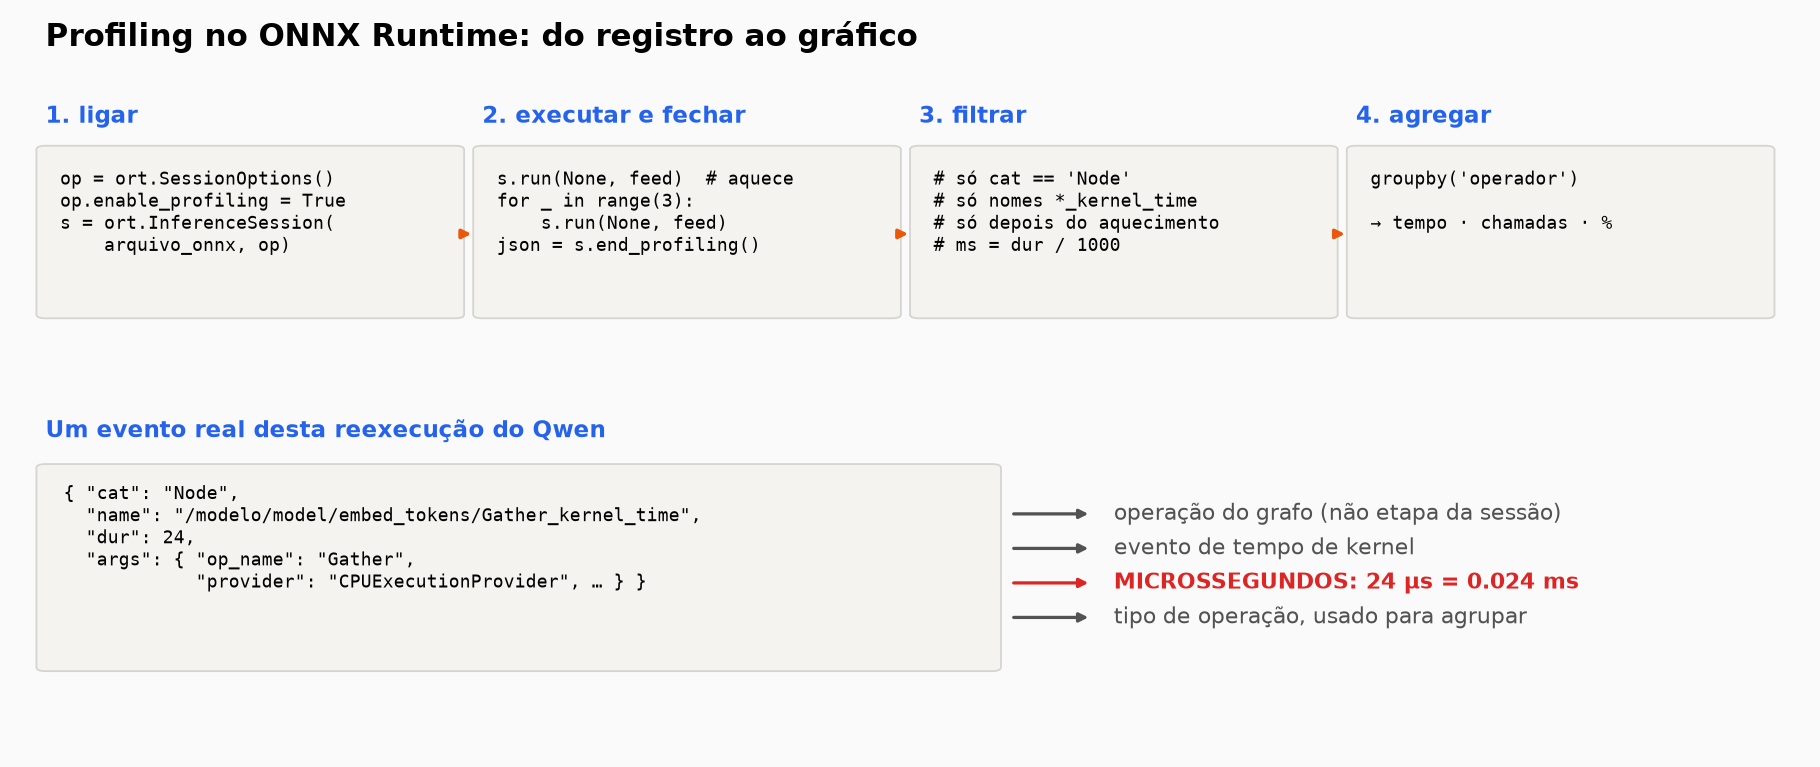

| Campo do JSON | O que significa |
|---|---|
| `cat` | `Node` = uma operação do grafo; `Session` = etapas amplas, como a carga ou a execução inteira (`model_run`) |
| `name` | Usamos os nomes terminados em `_kernel_time`: o tempo do **kernel**, a implementação da operação na CPU |
| `dur` | Duração em **microssegundos**; dividimos por 1.000 para ter ms. As figuras do livro rotulam o eixo como ms. |
| `args.op_name` | Tipo do operador (`MatMul`, `Add`, `QuickGelu`…), usado para agrupar |

**Três cuidados ao ler o perfil:**
1. **Não some `Session` com `Node`.** O evento `model_run` já contém os nós; somar os dois conta o mesmo trabalho duas vezes.
2. **Descarte o aquecimento.** `resumir_perfil` considera só as três últimas execuções `model_run`; a primeira fica de fora.
3. **Separe perfil de cronômetro.** Registrar eventos tem custo; latência se mede em outra sessão, com o profiler desligado.

| Na tabela da célula | O que calcula e qual é o denominador |
|---|---|
| `chamadas` | Eventos de kernel somados nas **3 execuções medidas** (divida por 3 para ter nós por prefill) |
| `ms_por_prefill` | Soma das durações ÷ 3: **média** por prefill, não a mediana do cronômetro |
| `participacao_%` | Fração da **soma dos kernels selecionados**; não inclui o que acontece fora deles |

In [ ]:
# @title Ler um evento e comparar duração, contagem e participação
perfil,evento=perfilar(ARQUIVO)
print({k:evento.get(k) for k in ['cat','name','dur']})
print('Operador:',evento['args']['op_name'],'· dur em microssegundos')
print(perfil[['ms_por_prefill','chamadas','participacao_%']].head(8).round(2).to_string())
top=perfil.head(6).iloc[::-1]
rotulos=[{'SimplifiedLayerNormalization':'RMSNorm','FusedMatMul':'MatMul fundida','QuickGelu':'SiLU (QuickGelu)'}.get(nome,nome) for nome in top.index]
fig,axes=plt.subplots(1,3,figsize=(11,3.4),sharey=True)
for ax,col,titulo in zip(axes,['ms_por_prefill','chamadas','participacao_%'],['Tempo por prefill (ms)','Chamadas em 3 prefills','Tempo dos kernels (%)']):
    barras=ax.barh(rotulos,top[col],color='#3b82f6')
    ax.bar_label(barras,fmt='%.1f',padding=3,fontsize=9)
    ax.set_xlim(0,max(top[col])*1.22)
    ax.set_title(titulo,fontsize=11);ax.grid(axis='x',alpha=.2)
fig.tight_layout();fig.savefig(PASTA/'perfil_qwen.png',bbox_inches='tight');plt.show()
mais_lento=perfil.index[0]
print(f"{mais_lento}: {perfil.iloc[0]['participacao_%']:.1f}% do tempo dos kernels.")

## 4. Do JSON ao gargalo: frequência versus custo

O livro usa o **Ort_perf_view**, um *treemap* com um bloco por operador (§10.2). Aqui agrupamos os milhares de eventos em três visões:

| Visão | Pergunta | Uso |
|---|---|---|
| **Tempo** por prefill (ms) | Onde o tempo foi? | Priorizar o gargalo |
| **Chamadas** em 3 prefills | O que mais se repete? | Achar candidatos a fusão |
| **Participação** (%) | Quanto pesa no total dos kernels? | Estimar o teto de ganho (Amdahl) |

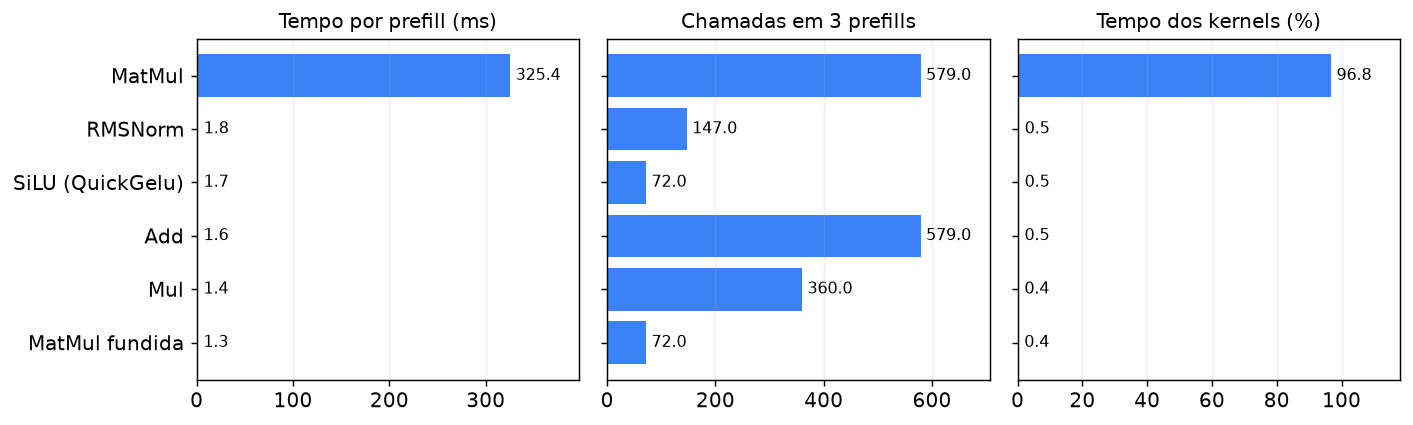

*Registro histórico, MacBook, 20/10/2026: perfil FP32 do Qwen, duas threads. Ao executar, a célula anterior mostra o seu gráfico e o grava em `PASTA/perfil_qwen.png`; esta imagem não muda.*

**Pergunta:** no registro, `Add` e `MatMul` têm 579 chamadas cada. Qual você otimizaria primeiro?

<details>
<summary>▸ Resposta e conferência dos denominadores</summary>

`MatMul`: 325,39 ms por prefill (96,8% dos kernels) contra 1,58 ms de `Add` (0,5%), cerca de 206 vezes mais. **Mais chamadas não significam mais tempo:** cem chamadas de 0,01 ms custam 1 ms; dez de 2 ms custam 20 ms.

As contagens fecham com a arquitetura de 24 camadas: `579 / 3 = 193` `MatMul` por prefill; `72 / 3 = 24` `QuickGelu` e `24` `FusedMatMul` (um por camada); `147 / 3 = 49` `SimplifiedLayerNormalization` (2 × 24 + 1 normalização final).

A soma dos kernels por prefill é `325,39 / 0,9677 ≈ 336,25 ms`. O cronômetro do prefill marcou 361,56 ms, mas em **outra sessão e com outra estatística** (mediana de 8 rodadas sem profiler × média de 3 execuções com profiler). A diferença de ~25 ms não pode ser atribuída quantitativamente a trabalho fora dos kernels. Note também que ler os pesos da memória acontece **dentro** dos kernels de multiplicação: esse custo já está nos 96,8%.
</details>

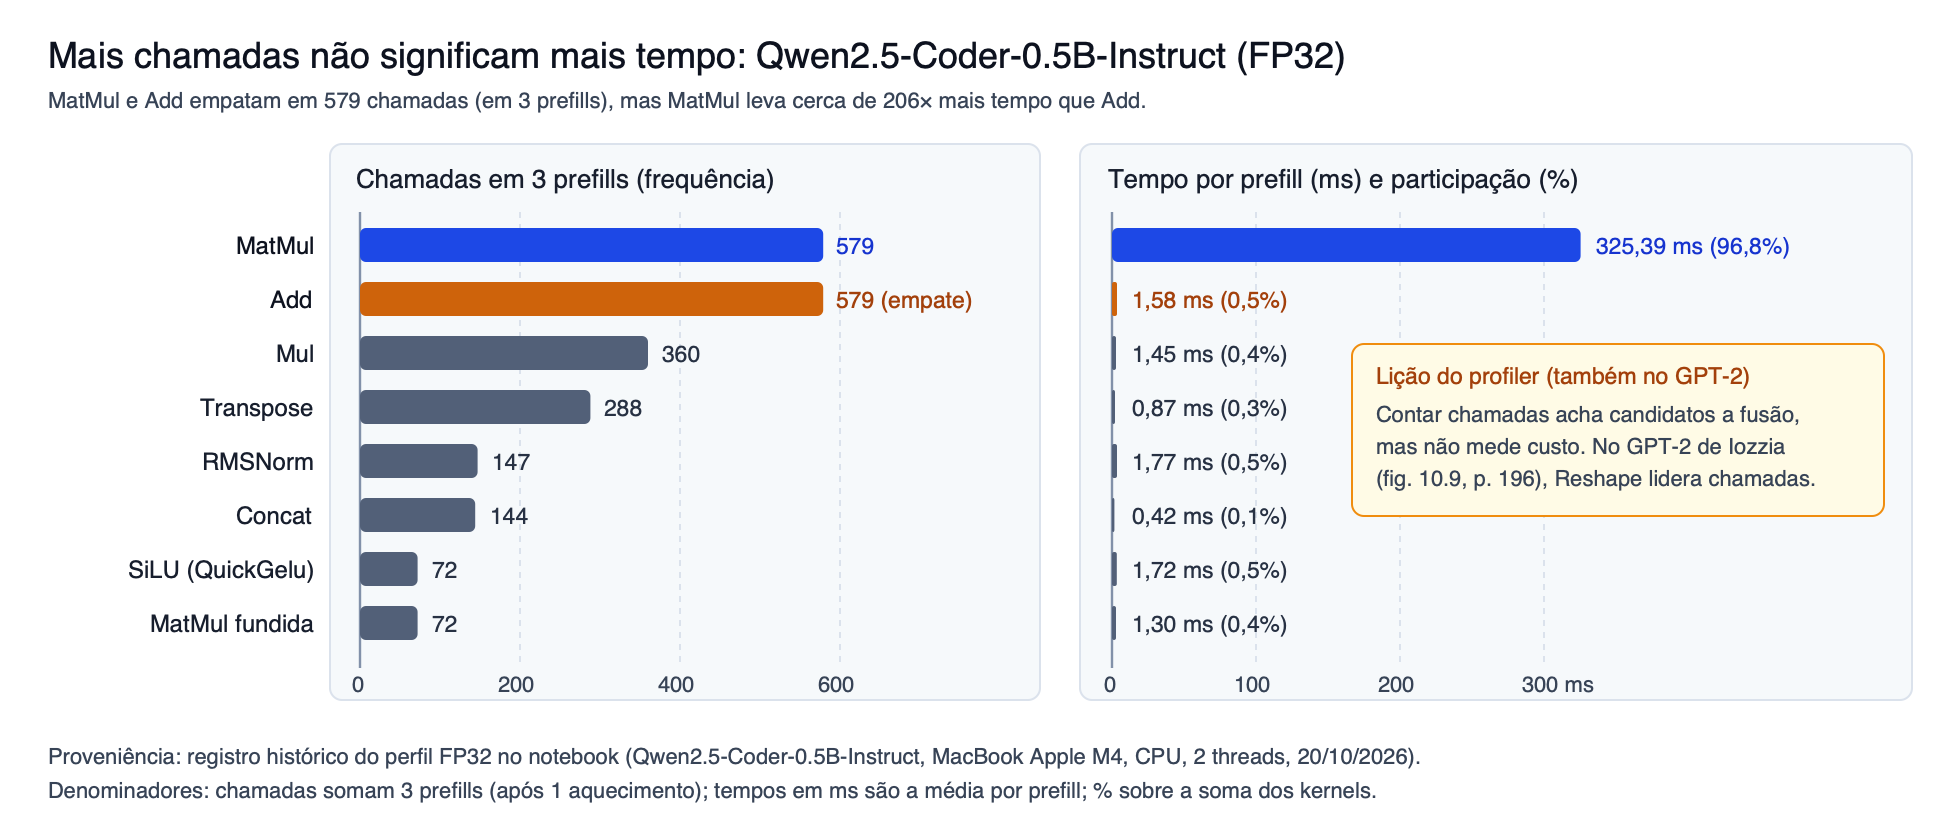

O livro mostra o mesmo fenômeno no GPT-2 (fig. 10.9): `Reshape` é o operador mais frequente sem ser o mais caro. **O alvo é a multiplicação de matrizes.**

Este perfil já usa otimizações de grafo: `sessao()` as habilita por padrão, e por isso aparecem `SimplifiedLayerNormalization` (RMSNorm), `QuickGelu` (a SiLU) e `FusedMatMul`, operadores **fundidos** pelo runtime. A seção 5 compara o grafo com e sem essas reescritas. No cálculo de Amdahl, `MatMul`, `FusedMatMul` e `Gemm` (produto de matrizes com escala e soma opcional) contam como multiplicações.

## 5. Otimização de grafo: reescrever sem mudar os pesos

Há duas famílias de otimização de inferência neste notebook: **otimização de grafo**, que reescreve a estrutura das operações e mantém os pesos em FP32, e **quantização**, que muda a representação numérica (seção 6).

Abrimos **o mesmo ONNX FP32 em duas sessões**: uma com as reescritas desligadas (`ORT_DISABLE_ALL`) e outra com todas habilitadas (`ORT_ENABLE_ALL`: níveis básico, estendido e de layout, quando aplicáveis à CPU).

| Na célula abaixo | O que faz |
|---|---|
| `nao = sessao(ARQUIVO, otimizar=False)` | Referência sem reescritas |
| `sim = sessao(ARQUIVO, salvar=OTIMIZADO)` | Habilita as otimizações e grava o grafo reescrito para inspeção. O arquivo gravado aponta para os pesos externos do original pelo nome, sem copiá-los; por isso fica na mesma pasta. |
| `pareado(...)` | Alterna as duas sessões, mesmo `feed` e mesmas threads |
| `assert_allclose(a, b, ...)` | Confere os logits com tolerância; também comparamos o próximo token |

A otimização acontece ao criar a sessão (**online**), antes do trecho cronometrado. Salvar o resultado permite reutilizá-lo (**offline**), respeitando a compatibilidade com a máquina e o *execution provider* ([documentação do ONNX Runtime](https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html)).

### Uma fusão concreta observada no Qwen

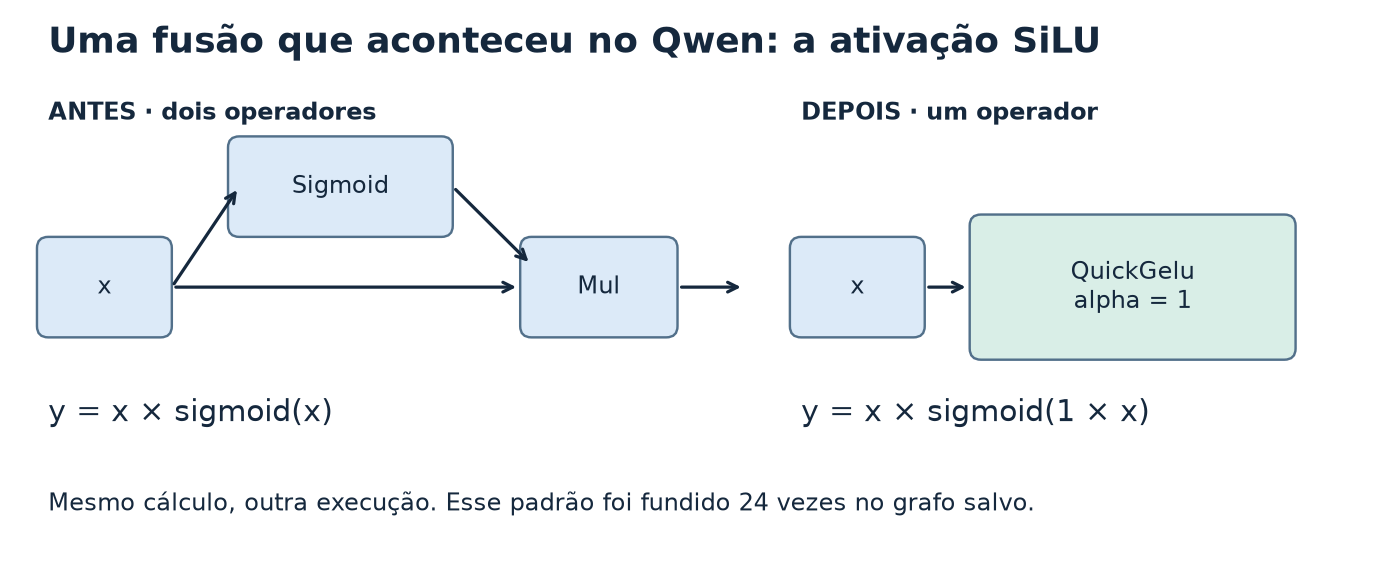

Apesar do nome, `QuickGelu` com `alpha=1` calcula `x × sigmoid(x)`, a **SiLU** do bloco SwiGLU. A fusão troca dois kernels, e o tensor intermediário entre eles, por um só. O padrão se repete nas 24 camadas:

| Padrão no ONNX original | No grafo otimizado | Ocorrências |
|---|---|---:|
| `Sigmoid(x)` seguido de `Mul(x, ...)` | `QuickGelu`, `alpha=1` | 24 |
| Operações da RMSNorm | `SimplifiedLayerNormalization` | 49 (2 × 24 + 1) |
| Transposição + multiplicação da atenção + escala | `FusedMatMul` | 24 |

Houve também cálculo antecipado de expressões constantes e remoção de nós redundantes. **Fusão reúne operações em um kernel**, o que pode reduzir chamadas e acessos intermediários à memória; o efeito no tempo precisa ser medido. No GPT-2 do livro aparecem `SkipLayerNormalization` e `FastGelu`, porque aquela arquitetura usa `LayerNormalization` e `Gelu`. O §10.3 também apresenta o `ReferenceEvaluator` do pacote `onnx`, que executa o grafo nó a nó para depurar valores intermediários.

In [ ]:
# @title Comparar o grafo antes e depois da otimização
# O ORT grava o grafo otimizado apontando para os arquivos de pesos do original: mesma pasta.
OTIMIZADO=ARQUIVO.parent/'qwen_otimizado.onnx'
sim=sessao(ARQUIVO,salvar=OTIMIZADO);nao=sessao(ARQUIVO,otimizar=False)
a=nao.run(None,feed)[0];b=sim.run(None,feed)[0]
np.testing.assert_allclose(a,b,rtol=1e-3,atol=1e-3)
grafo=pareado({'Sem otimizações':nao,'Com otimizações':sim},feed)
print(grafo.round(2).to_string())
contagens=[]
for nome,caminho in [('Original',ARQUIVO),('Otimizado',OTIMIZADO)]:
    m=onnx.load(str(caminho),load_external_data=False);ct=Counter(no.op_type for no in m.graph.node)
    contagens.append({'grafo':nome,'nós':len(m.graph.node),'MatMul':ct['MatMul'],'FusedMatMul':ct['FusedMatMul'],
                      'arquivo_MB':tamanho_mb(caminho)})
    del m
print(pd.DataFrame(contagens).set_index('grafo').round(1).to_string())
ganho_grafo=grafo.loc['Sem otimizações','mediana_ms']/grafo.loc['Com otimizações','mediana_ms']
print(f"Razão das medianas: {ganho_grafo:.2f}×. Mediana das razões por bloco: "
      f"{razao_pareada(grafo,'Sem otimizações','Com otimizações'):.2f}×. Acima de 1 significa aceleração.")
print('Próximo token igual:',bool(a[0,-1].argmax()==b[0,-1].argmax()))
del sim,nao,a,b;liberar_memoria()

### Leitura do resultado e a Lei de Amdahl

*Registro histórico, MacBook, 20/10/2026. A coluna `FusedMatMul` foi contada no grafo salvo naquela rodada; a razão por bloco não existia no código de então.*

| Medida | Sem otimizações | Com otimizações |
|---|---:|---:|
| Nós no grafo | 2.983 | 1.116 (−62,6%) |
| `MatMul` / `FusedMatMul` | 218 / 0 | 193 / 24 |
| Modelo e pesos referenciados, MB | 2.521,34 | 2.521,16 (os mesmos arquivos de pesos) |
| Mediana de um prefill, ms | 442,56 | 382,79 (razão 1,16×) |
| Mínimo / máximo, ms | 334,87 / 1.011,94 | 335,25 / 677,17 |
| Saída para o pedido testado | Referência | Logits próximos e mesmo próximo token |

O grafo perdeu 1.867 nós, os pesos continuaram em FP32 e a razão das medianas foi 1,16×. Os mínimos quase iguais (334,87 e 335,25 ms) e os máximos altos indicam que parte da diferença entre medianas pode ser ruído desta rodada: o ganho do grafo é **incerto** sem mais repetições, e não atribuímos a causa desse 1,16× sem um perfil antes/depois comparando `ORT_DISABLE_ALL` e `ORT_ENABLE_ALL`. Note também que manter os pesos em FP32 não garante que o tempo das multiplicações fique invariável (otimizações de layout, kernel ou fusão podem acelerá-las sem trocar precisão). **Contar nós não equivale a medir custo.** Na execução de 25/11/2026 em Linux ARM64 com grafo dinâmico (outro ambiente e outro ensaio), a otimização cortou 5.885 → 2.581 nós com mediana de 330,10 → 328,06 ms (1,01×; razão por bloco 1,00×), desafio discutido na seção **Além do livro** logo após o fechamento.

### Amdahl: quanto da execução a mudança alcança?

A Lei de Amdahl (Amdahl, AFIPS 1967) estima a aceleração total $S$ quando uma fração $f$ do tempo fica $k$ vezes mais rápida e o **tempo** do restante $(1-f)$ permanece invariável no mesmo perfil de referência:

$$S = \frac{1}{(1 - f) + \frac{f}{k}}$$

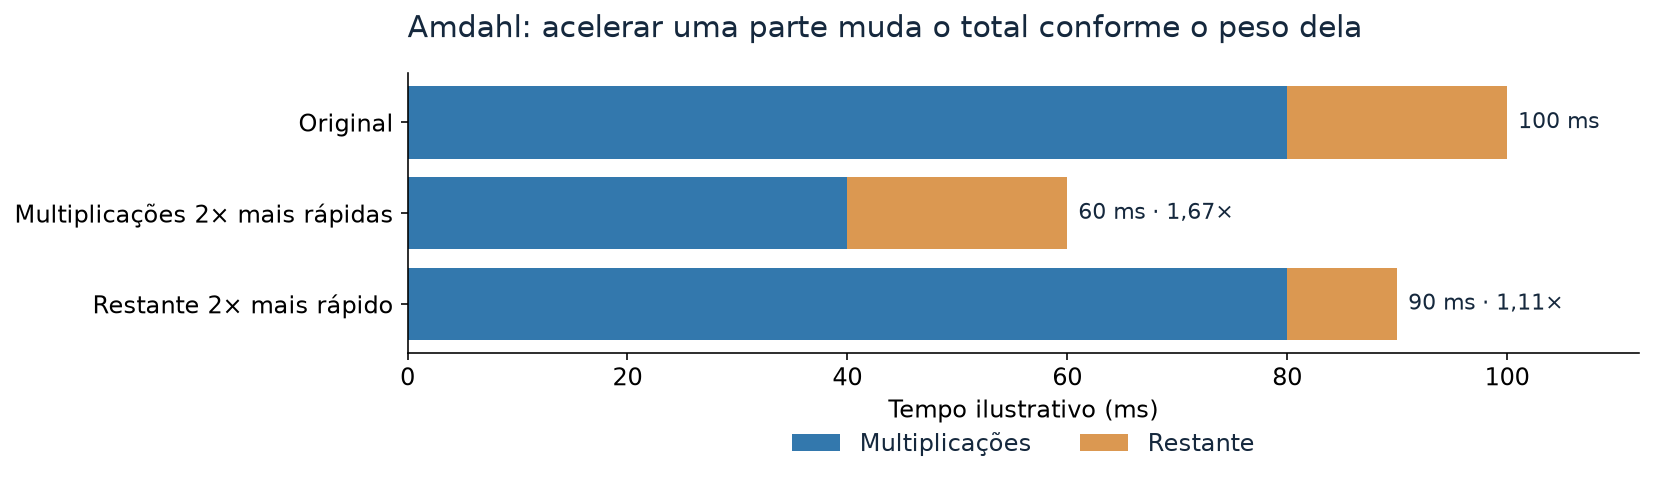

*Exemplo didático, sem medições:* com 80% do tempo nas multiplicações, dobrar a velocidade delas leva 100 ms a 60 ms (1,67×); dobrar o restante leva só a 90 ms (1,11×).

A célula seguinte aplica a fórmula ao perfil **já otimizado** do Qwen (seção 4), com `k = 2` e `f` = fração dos kernels em multiplicações. Como `f = 97,2%` vem do grafo já otimizado, ela não serve de teto retroativo da passagem do grafo não otimizado para o otimizado; serve para priorizar o **próximo passo**. **Pergunta:** nesse mesmo perfil de referência (`f = 97,2%` no registro), qual é o ganho máximo nos kernels se o restante (2,8%) ficasse com custo **zero** mantendo o **tempo** das multiplicações invariável?

<details>
<summary>▸ Resposta</summary>

`1 / 0,972 ≈ 1,03×`. A partir do perfil já otimizado, otimizar só operadores periféricos sem reduzir o tempo das multiplicações tem retorno pequeno; o próximo passo é atacar as multiplicações. A conta usa o tempo dos kernels, não a latência medida pelo cronômetro.
</details>

In [ ]:
# @title Estimar o efeito de acelerar as multiplicações
fracao=perfil.loc[perfil.index.str.contains('MatMul|Gemm'),'total_ms'].sum()/perfil.total_ms.sum()
print(f"Multiplicações: {fracao:.1%} do tempo dos kernels.")
print(f"Se elas ficassem 2× mais rápidas: ganho estimado de {1/((1-fracao)+fracao/2):.2f}× no total de kernels.")
print(f"Ganho medido da otimização do grafo: {ganho_grafo:.2f}× no prefill.")

## 6. Quantização dinâmica INT8 nas multiplicações

Agora mudamos a **representação numérica** das multiplicações de matrizes, como no capítulo 7 do livro.

| Formato | Bits por valor | Papel |
|---|---:|---|
| FP32 | 32 | Ponto flutuante de referência neste experimento |
| FP16 | 16 | Menos bits para expoente e fração; na CPU pode exigir conversões caras (fechamento) |
| BF16 | 16 | Mantém a faixa de expoentes do FP32, com menos precisão na fração |
| INT8 | 8 | Inteiros; escalas relacionam esses números aos valores em ponto flutuante |

*Analogia:* FP32 é um paquímetro de alta resolução; INT8 é uma régua de 256 marcas acompanhada de um fator de escala. Ocupa menos memória e permite instruções inteiras, ao custo de arredondamento. Bits por valor não equivalem ao tamanho do arquivo: embeddings, normas e escalas continuam em ponto flutuante.

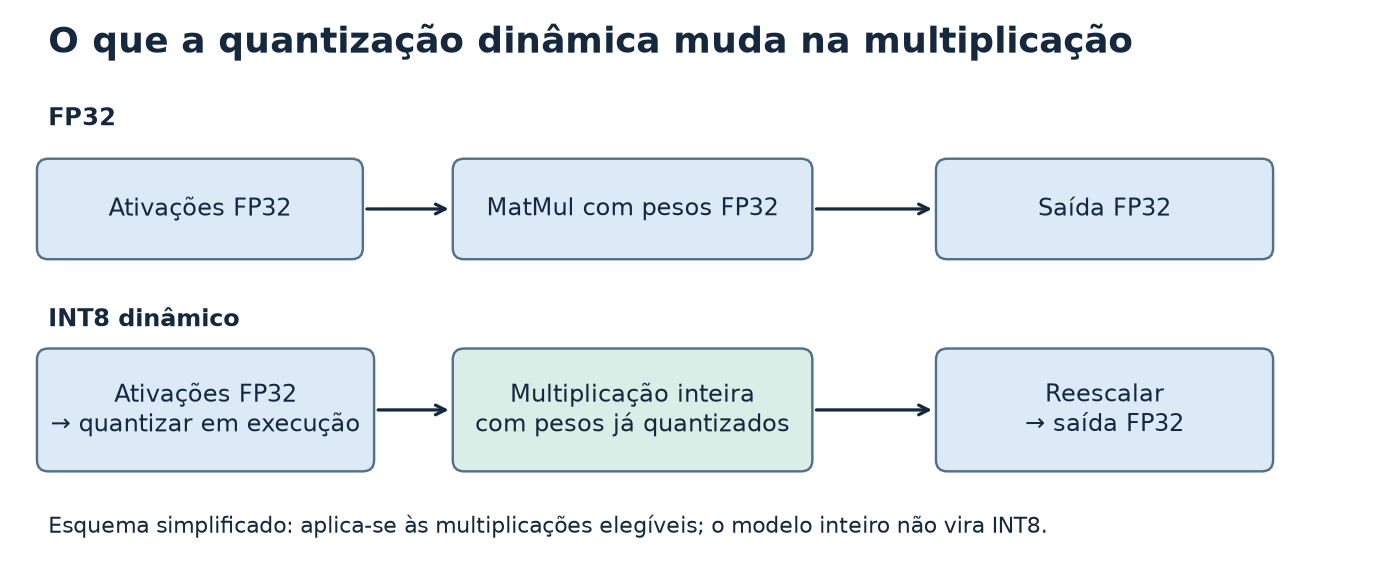

| O que muda na quantização dinâmica | Quando acontece |
|---|---|
| Pesos das multiplicações elegíveis viram `QInt8` | Uma vez, ao gravar o arquivo INT8 |
| Ativações são quantizadas conforme a faixa observada (`uint8` nesta versão do ORT) | Em cada chamada |
| O produto inteiro é reescalado para ponto flutuante | Na inferência |
| Demais operações, como a busca de embeddings e as normalizações | Continuam em ponto flutuante |

`quantizar_int8(ARQUIVO, INT8)` chama `quantize_dynamic` do ONNX Runtime com estes argumentos:

| Argumento de `quantize_dynamic` | Efeito |
|---|---|
| `weight_type=QuantType.QInt8` | Pesos em inteiros de 8 bits com sinal |
| `op_types_to_quantize=['MatMul']` | Seleciona a família que domina o perfil |
| `extra_options={'MatMulConstBOnly': True}` | Só `MatMul` com a segunda entrada constante (pesos das projeções); produtos entre ativações, como na atenção, ficam em ponto flutuante |

<details>
<summary>▸ Por que a quantização roda em outro processo (contorno de memória do ORT 1.20.1)</summary>

Na execução de 25/11/2026, num contêiner limitado a 6,5 GiB de RAM, a chamada direta a `quantize_dynamic` foi encerrada por falta de memória, e ela também não coube em 7 GiB rodando sozinha. A causa está num comportamento interno do ORT 1.20.1: no modo dinâmico, `quantize_dynamic` já infere formas ao carregar e, no construtor, grava e **recarrega o modelo inteiro** para atualizar `ValueInfo` depois de trocar `Gemm` por `MatMul`, mantendo a cópia anterior viva (duas cópias de ~2,5 GB antes de criar os pesos INT8).

`quantizar_int8` libera memória retida no processo pai (`liberar_memoria()`), executa a quantização em processo separado e aplica um **contorno de memória específico da versão 1.20.1**: só quando `onnxruntime.__version__ == '1.20.1'` **e** o grafo não contém nós `Gemm` (caso do Qwen), pula essa recarga redundante. **Isso não é uma API pública nem é garantido para outras versões do ORT**; em qualquer outra versão ou em grafos com `Gemm`, o código executa `quantize_dynamic` sem alteração. Pico isolado medido no contêiner: ~5,0 GiB; testes diferenciais em modelos pequenos (com e sem `Gemm`) e num Qwen2 minúsculo confirmam nós, inicializadores e saídas idênticos ao `quantize_dynamic` padrão.
</details>

A quantização arredonda valores e acrescenta conversões. Por isso voltamos ao ciclo: **cronometrar em par, perfilar por família e conferir a saída.** FP32 e INT8 são medidos intercalados na mesma célula; não compare o INT8 com a mediana FP32 de outra célula.

In [ ]:
# @title Quantizar, medir e conferir a saída
INT8=PASTA/'qwen_int8.onnx'
quantizar_int8(ARQUIVO,INT8)  # quantize_dynamic em outro processo; argumentos no texto acima
s32=sessao(ARQUIVO);s8=sessao(INT8)
y32=s32.run(None,feed)[0];y8=s8.run(None,feed)[0]
# Rejeita NaN e infinito; valores finitos ainda podem levar a uma resposta errada.
assert np.isfinite(y8).all()
quantizacao=pareado({'FP32':s32,'INT8':s8},feed)
quantizacao['arquivo_MB']=[tamanho_mb(ARQUIVO),tamanho_mb(INT8)]
print(quantizacao.round(2).to_string())
ganho_int8=quantizacao.loc['FP32','mediana_ms']/quantizacao.loc['INT8','mediana_ms']
print(f"Razão FP32/INT8 das medianas: {ganho_int8:.2f}×. Mediana das razões por bloco: {razao_pareada(quantizacao,'FP32','INT8'):.2f}×.")
print(f"Diferença absoluta média dos logits: {np.abs(y32-y8).mean():.4f}")
print('Próximo token igual:',bool(y32[0,-1].argmax()==y8[0,-1].argmax()))
print('Conferência deste prefill; não comprova a correção de uma geração inteira quantizada.')
del s32,s8;liberar_memoria()
proximos=[]
for nome,y in [('FP32',y32),('INT8',y8)]:
    token_id=int(y[0,-1].argmax())
    proximos.append({'variante':nome,'ID':token_id,'próximo token':repr(tokenizer.decode([token_id]))})
print(pd.DataFrame(proximos).set_index('variante').to_string())
if y32[0,-1].argmax()!=y8[0,-1].argmax():
    print('A escolha do próximo token mudou. Precisamos avaliar a geração completa antes de adotar esta quantização.')
del y32,y8;liberar_memoria()

In [ ]:
# @title Localizar a mudança de custo
p32,_=perfilar(ARQUIVO);p8,_=perfilar(INT8)
def familia(nome):
    if 'MatMul' in nome or 'Gemm' in nome:return 'Multiplicações'
    if 'Quantiz' in nome:return 'Quantização'
    return 'Demais operações'
comparar=pd.DataFrame({nome:p.assign(familia=[familia(o) for o in p.index]).groupby('familia').ms_por_prefill.sum()
                      for nome,p in [('FP32',p32),('INT8',p8)]}).fillna(0)
print(comparar.round(2).to_string())
ax=comparar.plot.barh(figsize=(8,2.8),color=['#64748b','#2563eb'])
ax.set_xlabel('Soma do tempo dos kernels por prefill (ms)');ax.set_ylabel('');ax.grid(axis='x',alpha=.2)
plt.tight_layout();plt.savefig(PASTA/'perfil_fp32_int8.png',bbox_inches='tight');plt.show()
print('Operadores fundidos de multiplicação quantizada ficam no grupo Multiplicações; o tempo deles já inclui trabalho interno de conversão.')

### Onde o tempo diminuiu?

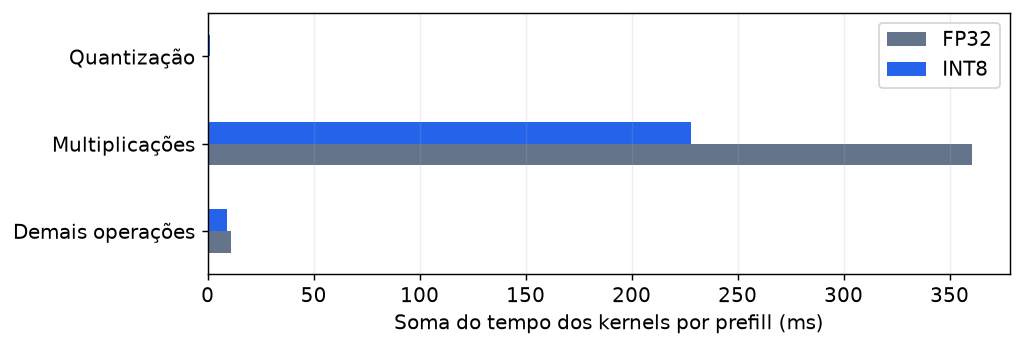

*Registro histórico, MacBook, 20/10/2026. Ao executar, **Localizar a mudança de custo** mostra o seu gráfico e o grava em `PASTA/perfil_fp32_int8.png`.*

| Medida no registro | FP32 → INT8 |
|---|---:|
| Multiplicações, ms por prefill (perfil) | 360,54 → 228,24 (1,58×) |
| Quantização explícita, ms por prefill (perfil) | 0 → 0,95 |
| Demais operações, ms por prefill (perfil) | 11,00 → 9,27 |
| Mediana pareada sem profiler, ms | 585,24 → 332,82 (razão 1,76×) |
| Modelo e pesos, MB | 2.521,34 → 1.039,88 |

**Pergunta:** com ~97% do tempo nas multiplicações e 1,58× nelas, quanto Amdahl prevê? Por que o cronômetro marcou 1,76×?

<details>
<summary>▸ Resposta</summary>

`1 / (0,03 + 0,97 / 1,58) ≈ 1,55×`. A diferença para 1,76× não tem uma causa isolada. Hipóteses compatíveis com o registro: (1) a conta usa perfis medidos antes e depois e supõe o restante fixo, sem ser previsão independente; (2) perfil e cronômetro vêm de sessões diferentes e de estatísticas diferentes (média de 3 execuções com profiler × mediana de 8 sem profiler); (3) o cronômetro inclui trabalho fora dos kernels, como despacho e cópia de entradas e saídas, enquanto a leitura dos pesos acontece dentro dos kernels e já está no perfil; (4) a rodada teve dispersão alta (máximo FP32 de 1.571,20 ms). A dispersão **não prova** que 1,76× está inflado; diz que a conclusão é incerta sem mais controle. Use 1,76× como retrato daquela rodada pareada, não como ganho garantido.
</details>

<details>
<summary>▸ Por que o INT8 não tem um quarto do tamanho?</summary>

Conta de consistência com a [configuração publicada](https://huggingface.co/Qwen/Qwen2.5-Coder-0.5B-Instruct/blob/ea3f2471cf1b1f0db85067f1ef93848e38e88c25/config.json), não uma medição nova. O modelo tem 494.032.768 parâmetros; 151.936 × 896 = 136.134.656 formam a tabela de embeddings, compartilhada com a camada de saída (`tie_word_embeddings: true`). O ONNX exportado guarda essa tabela duas vezes: na busca de embeddings (`Gather`) e como peso do último `MatMul`. Em FP32: (494.032.768 + 136.134.656) × 4 bytes ≈ 2.520,7 MB, próximo dos 2.521,34 MB medidos. No INT8, só os pesos de `MatMul` passam a 1 byte: a cópia do `Gather` continua em FP32 (≈ 544,5 MB) e os ≈ 494 milhões de pesos restantes ocupam ≈ 494 MB; soma ≈ 1.039 MB, próxima dos 1.039,88 MB medidos. MB aqui é 10⁶ bytes.
</details>

O próximo token do prefill mudou no registro: ``'```'`` em FP32 e `'def'` em INT8, com diferença absoluta média de 1,2511 nos logits. Um token diferente no início não diz se a função final ficou errada. A seção 7 gera respostas inteiras.

## 7. A resposta continua correta? Três tarefas em FP32 e INT8

Conferir um prefill não basta: precisamos gerar a resposta inteira e testá-la. O registro de 20/10/2026 fez isso com uma tarefa:

*Registro histórico, MacBook, 20/10/2026 (código anterior, só `media`).*

| Conferência | FP32 | INT8 |
|---|---|---|
| Função gerada | `media(numeros)` | `mean(numbers)` |
| Casos | 7/7 | 7/7 |
| Nome pedido `media` | respeitado | trocado |
| Fim por EOS | sim, 36 tokens | sim, 26 tokens |

Uma tarefa é pouco. Esta versão avalia **três tarefas**, escolhidas para caber na contenção da seção 1 (uma função, um parâmetro, sem laços nem atributos) e para diferir no que exigem:

| Tarefa | Entrada | Chamadas liberadas | Casos | O que exige |
|---|---|---|---:|---|
| `media(numeros)` | lista de números | `sum`, `len` | 7 | reduzir uma lista; tratar a lista vazia |
| `sinal(numero)` | um número | nenhuma | 6 | ramificar em três saídas: 1, −1 ou 0 |
| `limitar(valor)` | um número | nenhuma | 7 | respeitar os limites inclusivos 0 e 100 |

O pedido de `media` é o mesmo do registro. Os de `sinal` e `limitar` pedem explicitamente só `if` e comparações, sem imports e sem chamar funções, porque nessas tarefas a contenção rejeita qualquer chamada (inclusive `max`, `min` e `abs`). Os textos completos estão em `TAREFAS`, na célula de funções.

### O laço de geração

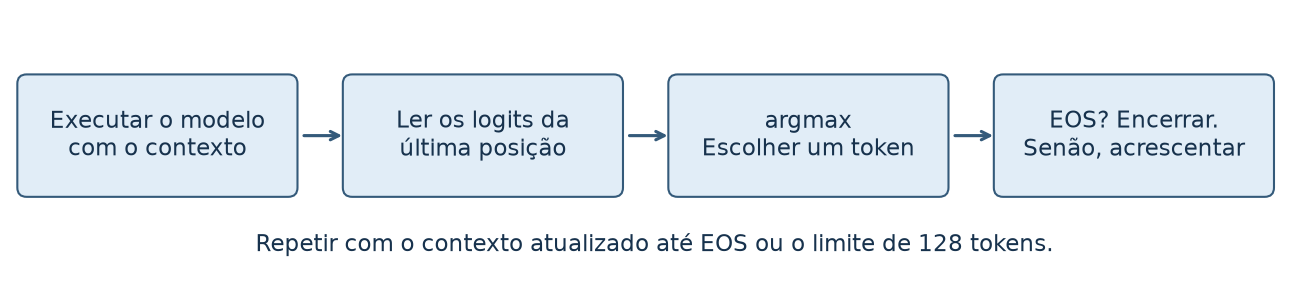

| Trecho de `gerar_gulosamente` / `gerar_para_tarefas` | Leitura |
|---|---|
| `logits[0, -1].argmax()` | Escolhe o próximo token pela maior pontuação **bruta** |
| `token in eos_ids` | Para em qualquer um dos dois EOS do modelo: 151645 ou 151643 |
| `np.concatenate(..., axis=1)` | Acrescenta o token ao contexto e reprocessa tudo (**sem cache KV**) |
| `dynamic_axes={... 1: 'sequencia' ...}` | Definido na exportação única da seção 2, permite que o comprimento da sequência cresça sem reexportar |
| `gerar_para_tarefas(sessao, modelos, ...)` | Abre cada modelo **uma vez**, gera as três tarefas e libera a sessão antes de abrir o próximo |

A célula reutiliza diretamente `ARQUIVO` (o prefill FP32 dinâmico exportado e validado em dois comprimentos na seção 2) e `INT8` (quantizado na seção 6), sem recarregar o PyTorch nem repetir exportação ou quantização. FP32 e INT8 seguem **exatamente a mesma regra**: mesmo pedido por tarefa, argmax sem `repetition_penalty`, mesmos EOS, limite de 128 tokens.

**Não compare com a resposta da seção 1.** O `generate` aplica `repetition_penalty=1.05`; este laço não. Uma diferença entre a resposta da seção 1 e a do laço FP32 vem da regra de escolha, não da quantização. A comparação válida é FP32 × INT8 dentro desta seção. O laço serve para validar respostas; por reprocessar o contexto, não mede latência de geração com cache.

### Como ler a tabela

| Coluna | Pergunta |
|---|---|
| `sintaxe` | O código extraído é Python válido? |
| `estrutura` | Uma função, um parâmetro, só nós e chamadas permitidos? Se não, os casos não rodam. |
| `contrato` | A função tem o nome pedido? |
| `casos` | Aprovados/total, chamando a função pelo nome que o modelo escreveu |
| `eos` | Terminou por EOS antes de 128 tokens? |
| `erro` | Motivo da rejeição, quando houver |

**Pergunta:** se o INT8 escrever `mean(numbers)` e passar em todos os casos, ele acertou?

<details>
<summary>▸ Resposta</summary>

Acertou o cálculo e errou o contrato. Um sistema que chama `media(...)` falharia com `NameError`. Por isso as colunas ficam separadas, em vez de uma nota única.
</details>

**Limite:** são três funções minúsculas de um parâmetro, com diversidade baixa: nenhuma usa laços, texto ou estruturas de dados, e a contenção exclui a maior parte do Python. O resultado diz se a quantização mudou estas respostas; não mede a qualidade geral do modelo para gerar código.

In [ ]:
# @title Gerar com FP32 e INT8 e avaliar as três tarefas
# Reutiliza o prefill dinâmico (ARQUIVO) da seção 2 e o quantizado (INT8) da seção 6, sem reexportar nem requantizar.
liberar_memoria()

def ids_do_pedido(pedido):
    texto = tokenizer.apply_chat_template([{'role':'user','content':pedido}],tokenize=False,add_generation_prompt=True)
    return tokenizer(texto,return_tensors='np')['input_ids'].astype(np.int64)

entradas = {nome: ids_do_pedido(t['pedido']) for nome, t in TAREFAS.items()}
geracoes = gerar_para_tarefas(sessao, {'FP32': ARQUIVO, 'INT8': INT8}, entradas, EOS_IDS, max_tokens=128)

linhas_avaliacao, respostas_completas = [], {}
for (variante, tarefa), g in geracoes.items():
    resposta_completa = tokenizer.decode(g['novos'],skip_special_tokens=True).strip()
    r = testar_codigo_gerado(resposta_completa, TAREFAS[tarefa]['casos'], tarefa, chamadas=TAREFAS[tarefa]['chamadas'])
    linhas_avaliacao.append(linha_da_avaliacao(variante, tarefa, g, r))
    respostas_completas[f'{variante}/{tarefa}'] = {'resposta': resposta_completa, 'prompt_tokens': entradas[tarefa].shape[1],
                                                   **g, **linhas_avaliacao[-1], 'detalhe_casos': r['casos'].to_dict('records')}
    print(f"\n{variante} · {tarefa} · {g['tokens']} tokens · terminou por EOS: {g['terminou']} · {g['segundos']} s")
    print(resposta_completa)
    if len(r['casos']) and not r['casos'].passou.all():
        print(r['casos'].to_string(index=False))

avaliacao = pd.DataFrame(linhas_avaliacao).set_index(['tarefa','variante']).sort_index()
print('\nUma linha por tarefa × variante:')
print(avaliacao.to_string())
(PASTA/'respostas_completas.json').write_text(json.dumps(respostas_completas,ensure_ascii=False,indent=2,default=str))
print('Laço guloso sem cache KV e sem repetition_penalty, igual para FP32 e INT8: valida respostas; não mede latência.')

## 8. Fechamento: arquivo menor garante execução mais rápida?

Reduzir bits economiza disco e memória, mas não garante aceleração em todo hardware. No fechamento do capítulo 10 (fig. 10.13), ao converter o GPT-2 para FP16, o operador **`Cast`** (conversão de tipo) aparece entre os maiores custos. O mesmo sinal apareceu no nosso Qwen em CPU:

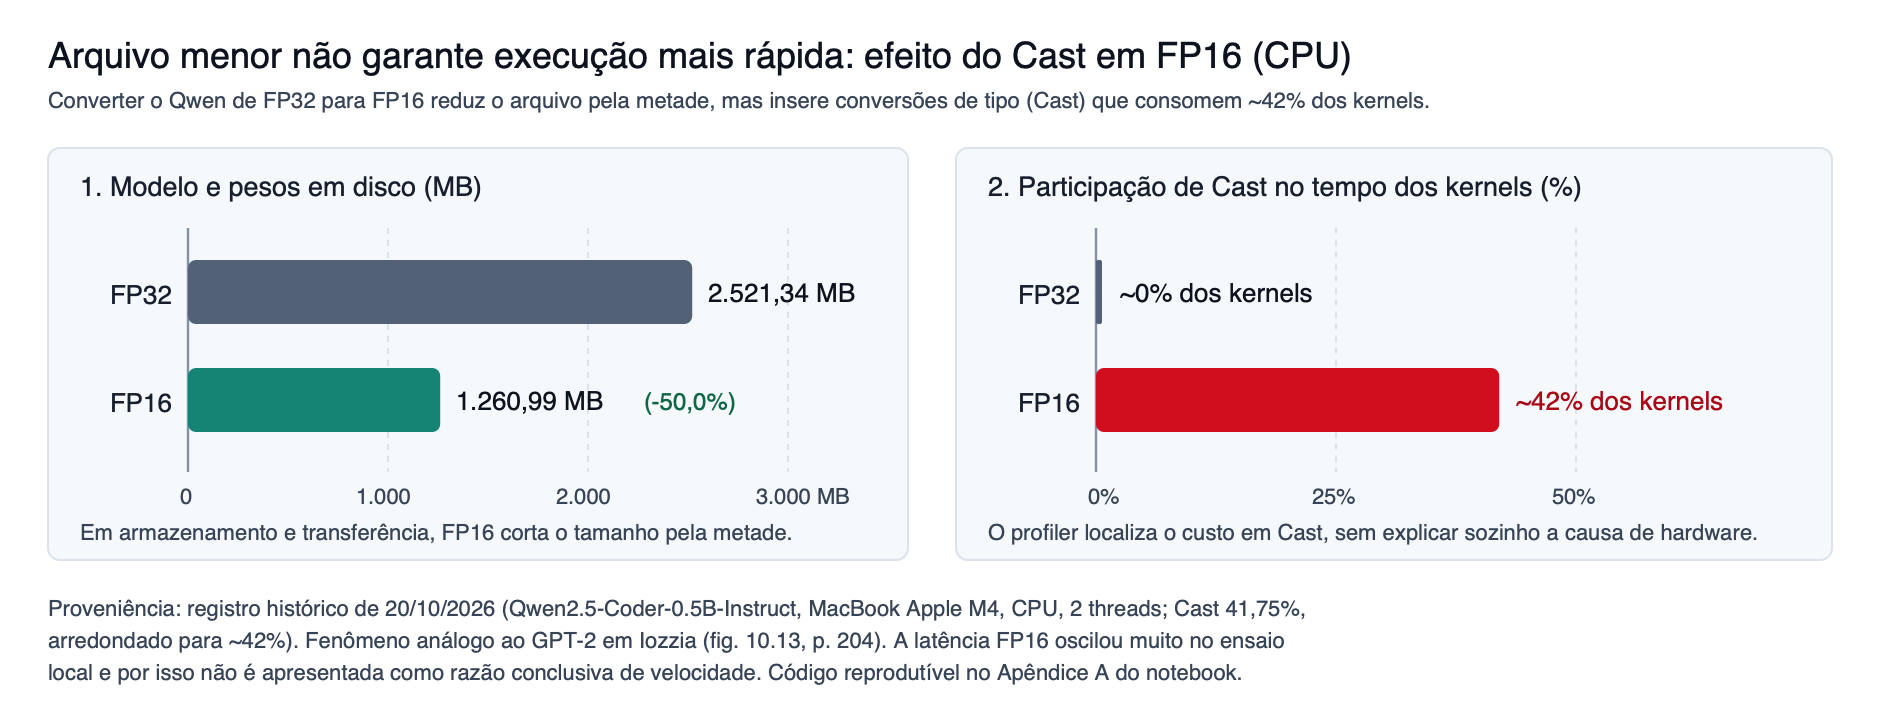

*Registro histórico, MacBook, 20/10/2026. O código desse ensaio está no apêndice A. Conversão com `keep_io_types=True` e `disable_shape_infer=True`; mesma medição pareada das outras seções. Medianas de 471,19 ms (FP32) e 610,72 ms (FP16), com dispersão alta.*

| No Qwen | FP32 | FP16 |
|---|---:|---:|
| Modelo e pesos, MB | 2.521,34 | 1.260,99 (−50%) |
| `Cast` no tempo dos kernels | ~0% | ~42% |

Um ensaio anterior, de 19/10/2026, registrou 46,49% para `Cast`. O arquivo encolheu, mas surgiu um custo alto de conversão. A latência oscilou; não usamos a razão FP32/FP16 como conclusão firme. O profiler **localiza** o custo em `Cast`; não explica sozinho a causa na CPU.

### O que levar do profiling

**Definir a medida → aquecer e repetir em par → ligar o profiler e filtrar eventos → localizar o gargalo com denominadores claros → estimar o teto com Amdahl → otimizar (grafo ou quantização) → cronometrar de novo e conferir a saída.**

### O que a avaliação prova e o que não prova

A seção 7 testa três funções pequenas com os mesmos pedidos e a mesma regra de geração em FP32 e INT8, separando sintaxe, estrutura, contrato, casos e término. Isso mostra se a quantização mudou **estas** respostas. Não mede a capacidade geral de gerar código: benchmarks como o [HumanEval](https://arxiv.org/abs/2107.03374) (Chen et al., 2021) usam 164 problemas, com testes unitários por problema e a métrica `pass@k`. Resultados de outra família de modelos, de outro toolkit ou de outro formato numérico não validam o nosso Qwen2.5-Coder no ONNX Runtime.

### Referências

Iozzia, *Domain-Specific Small Language Models*, capítulos 7 e 10. [Qwen2.5-Coder-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-Coder-0.5B-Instruct) e [Hui et al., 2024, arXiv:2409.12186v3](https://arxiv.org/abs/2409.12186v3). ONNX Runtime: [profiling](https://onnxruntime.ai/docs/performance/tune-performance/profiling-tools.html), [otimizações de grafo](https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html), [quantização](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html). Amdahl, AFIPS 1967. [Williams, Waterman e Patterson, 2009](https://doi.org/10.1145/1498765.1498785). [HumanEval, Chen et al., 2021](https://arxiv.org/abs/2107.03374). Fundamentos modernos (2022/2023): [FlashAttention, Dao et al., 2022](https://arxiv.org/abs/2205.14135); [Speculative Decoding, Leviathan et al., 2022/ICML 2023](https://arxiv.org/abs/2211.17192). Estudos de 2026: [Cai et al., 2026v2 (SIGMETRICS 2027)](https://arxiv.org/abs/2607.05475v2); [Harada, Alba e Luque, 2026 (preprint v1)](https://arxiv.org/abs/2607.20806). Guia: [`wiki.md`](https://github.com/luizpaulobarroca/IAG-2026-SLM/blob/docs/slm-profiling-wiki-20261125/content/small-language-model/practice/profiling/overview.md). Catálogo: [`docs/research/2026-11-25-profiling-alem-do-basico.md`](docs/research/2026-11-25-profiling-alem-do-basico.md).

## Além do livro: hipóteses, memória, hardware e fronteira de Pareto

As seções anteriores cobrem o ciclo clássico do capítulo 10. Mas um número real da nossa execução de **25/11/2026** (Linux ARM64, grafo dinâmico) mostra por que o trabalho do engenheiro não acaba no primeiro gráfico: a otimização de grafo cortou **5.885 → 2.581 nós** (−56,1%), enquanto a mediana pareada do prefill ficou em **330,10 → 328,06 ms** (razão das medianas **1,01×**; mediana das razões por bloco **1,00×**).

Esse 1,01× **não prova causa nem diferença estatisticamente detectável**. Os 97% do registro histórico de 20/10 pertencem a outro ambiente e grafo, portanto não explicam este resultado. Podemos investigar três hipóteses, que não são mutuamente exclusivas:

1. **As regiões reescritas já custavam pouco.** Mapear regiões equivalentes nos perfis `ORT_DISABLE_ALL` e `ORT_ENABLE_ALL`, pois fusão e reescrita mudam os nós e kernels.
2. **O custo dominante quase não mudou.** Comparar os tempos de `MatMul` e `FusedMatMul` antes e depois. Contadores de memória, se disponíveis, ajudam a investigar se o tráfego limita o ganho.
3. **O ruído encobriu uma diferença pequena.** Repetir o ensaio pareado com `N` maior e menos carga concorrente para analisar a dispersão por bloco. A diferença observada foi de cerca de 2 ms em 330 ms, com `N = 8`.

A redução de 3.304 na contagem é líquida: não significa necessariamente 3.304 operações removidas uma a uma.

Quatro ideias ampliam esse raciocínio além do livro (aprofundadas na seção 6 de [`wiki.md`](https://github.com/luizpaulobarroca/IAG-2026-SLM/blob/docs/slm-profiling-wiki-20261125/content/small-language-model/practice/profiling/overview.md)):

### Tráfego de memória e Roofline (2009 / 2022)

A **intensidade aritmética** (`FLOPs/byte` transferido no nível de memória analisado, por exemplo entre DRAM e caches) e o teto $\min(\text{pico computacional}, \text{banda} \times \text{intensidade})$ ([Williams, Waterman e Patterson, 2009](https://doi.org/10.1145/1498765.1498785)) funcionam aqui como modelo de raciocínio (não medimos banda neste notebook). Esse teto não prova saturação de memória; latências e lançamento de kernels podem limitar antes dele. Quando medições confirmam a limitação por banda, reorganizar acessos pode importar mais que contar operações: em GPU, o **FlashAttention** ([Dao et al., 2022](https://arxiv.org/abs/2205.14135)) calcula a atenção **exata** em blocos para reduzir idas entre HBM e SRAM, sem tornar a complexidade quadrática linear nem ser testado em CPU aqui. *Prefill* e *decode* costumam trocar de gargalo conforme lote, contexto e kernel, sem ser lei universal.
### Speculative decoding (2022/2023)

Um modelo menor propõe vários tokens e o modelo alvo verifica todos em paralelo ([Leviathan, Kalman e Matias, 2022/ICML 2023](https://arxiv.org/abs/2211.17192)). O método exato de amostragem, com aceitação e correção das propostas, preserva a distribuição alvo, mas não garante a mesma sequência para a mesma semente nem aceleração em qualquer carga (depende da taxa de aceitação e dos custos relativos). Não está implementado neste notebook.
### Hardware e fase (2026)

[Cai et al. (2026v2, SIGMETRICS 2027)](https://arxiv.org/abs/2607.05475v2) avaliaram cinco frameworks em CPU, GPU e NPU móveis e encontraram a NPU forte no *prefill* e a CPU melhor no *decode* nos cenários medidos. Sem extrapolar para este ambiente, a lição é clara: hardware, framework e fase decidem qual executor vence.
### Fronteira de Pareto e PTME (2026)

[Harada, Alba e Luque (2026, preprint v1 sem revisão por pares declarada)](https://arxiv.org/abs/2607.20806) usam um desktop com recursos limitados para aproximar envelopes restritos e avaliam juntos qualidade de tarefa (*Precision* no PTME, referindo-se a acerto da tarefa, não a FP16/INT8), tempo, pico de RAM e energia. Uma opção **domina** outra quando não perde em nenhum eixo e vence em ao menos um; a **fronteira de Pareto** reúne as opções não dominadas, onde melhorar um critério exige ceder em outro. **Energia não foi medida** neste notebook. O pico de RAM registrado pelo executor cobre o percurso do contêiner, sem picos comparáveis separados por variante; não construímos uma fronteira de Pareto empírica local.

## Exercícios de fixação

Tente responder antes de abrir a solução. Mais exercícios (incluindo desenho de experimento) e o glossário estão em [`wiki.md`](https://github.com/luizpaulobarroca/IAG-2026-SLM/blob/docs/slm-profiling-wiki-20261125/content/small-language-model/practice/profiling/overview.md).

1. **Unidades e denominadores.** Um evento `Node` terminado em `_kernel_time` traz `dur = 450`. O operador aparece 72 vezes somadas nas 3 execuções medidas. Quantos milissegundos durou esse evento? Quantos nós desse tipo há em um prefill?
   <details><summary>▸ Solução</summary><code>450 / 1000 = 0,45 ms</code>; <code>72 / 3 = 24</code> nós por prefill, um por camada do Qwen.</details>

2. **Amdahl.** Multiplicações somam 97,2% do tempo dos kernels. Qual o ganho máximo se todas as outras operações (2,8%) passassem a custar zero?
   <details><summary>▸ Solução</summary>Restariam 97,2% do tempo: <code>1 / 0,972 ≈ 1,03×</code>. Limpar operadores periféricos rende pouco.</details>

3. **Comparação válida.** No registro, o prefill FP32 teve mediana de 361,56 ms em **Exportar o prefill** e o INT8, 332,82 ms em **Quantizar, medir e conferir a saída**. Por que não concluir que o INT8 acelerou só 1,09×?
   <details><summary>▸ Solução</summary>As duas medianas vêm de ensaios em momentos diferentes, numa máquina não isolada: dentro da medição da quantização, o mesmo FP32 teve mediana de 585,24 ms. Só se comparam variantes medidas intercaladas no mesmo ensaio pareado. Mesmo assim, a alternância reduz o viés de ordem, mas não o elimina.</details>

4. **Escolha de token.** A resposta FP32 do laço da seção 7 para `media` difere da resposta do `generate` na seção 1. Isso indica um erro na exportação?
   <details><summary>▸ Solução</summary>Não necessariamente. O <code>generate</code> aplica <code>repetition_penalty=1.05</code> antes do argmax; o laço ONNX usa os logits brutos. Regras diferentes podem escolher tokens diferentes. A exportação é conferida por <code>assert_allclose</code> nos logits; a quantização, comparando FP32 e INT8 com a mesma regra.</details>

5. **Contrato versus cálculo.** Uma resposta passa em todos os casos de `limitar`, mas usa `max(0, min(100, valor))`. Por que a tabela marca `estrutura = False` e não roda os casos?
   <details><summary>▸ Solução</summary>Nessa tarefa a contenção não libera nenhuma chamada, e o pedido proibia chamar funções. A validação estrutural acontece antes de executar qualquer código; respostas fora da lista permitida não rodam. O cálculo poderia estar certo, mas a resposta descumpriu a restrição pedida.</details>

6. **Queda de nós e hipótese testável (ensaio de 25/11/2026).** Na execução de 25/11/2026, cortar 5.885 → 2.581 nós resultou em 330,10 → 328,06 ms (1,01×; razão por bloco 1,00×). Que medição simples ajuda a distinguir "os nós removidos já custavam pouco" de "o ruído mascarou o efeito"?
   <details><summary>▸ Solução</summary>Coletar o perfil de kernels antes e depois (<code>ORT_DISABLE_ALL</code> vs. <code>ORT_ENABLE_ALL</code>) no mesmo grafo dinâmico para comparar custos de regiões equivalentes, respeitando a mudança de nós e kernels por fusão, e repetir o ensaio pareado com <code>N</code> maior e menos carga concorrente para inspecionar a dispersão por bloco. Ver discussão completa nos exercícios 6 e 7 de <code>wiki.md</code>.</details>

7. **Fronteira de Pareto (dados hipotéticos).** Considere três variantes hipotéticas (não medidas aqui): **A** (78% acerto, 420 ms, 2,8 GiB, 6,0 J), **B** (75% acerto, 460 ms, 3,1 GiB, 6,8 J) e **C** (74% acerto, 190 ms, 1,4 GiB, 2,9 J). Qual é dominada e quais ficam na fronteira de Pareto?
   <details><summary>▸ Solução</summary><strong>B</strong> é dominada por <strong>A</strong> em todos os quatro critérios. <strong>A</strong> e <strong>C</strong> ficam na fronteira de Pareto: <strong>A</strong> acerta mais, enquanto <strong>C</strong> é mais rápida, leve e econômica (energia é hipotética aqui e não foi medida no notebook).</details>

## Apêndice A · Medição FP16 (opcional)

Esta célula reproduz o ensaio que gerou a tabela FP16 do fechamento. Ela vem da versão completa do notebook executada em 20/10/2026 e fica aqui para que a tabela tenha código correspondente.

| Escolha | Motivo |
|---|---|
| `convert_float_to_float16` do pacote `onnxruntime.transformers`, chamado por `converter_fp16` em outro processo | Converte pesos e operações para FP16 e insere `Cast` onde o tipo muda. A conversão carrega o FP32 inteiro (pico de ~5 GiB medido), por isso roda à parte, como a quantização |
| `keep_io_types=True` | Preserva os tipos originais de entrada e saída: IDs dos tokens e máscara em INT64, logits em FP32 |
| `disable_shape_infer=True` | A inferência de formas serializa o modelo inteiro e falha acima de 2 GB, o limite do protobuf |

Requer mais ~1,3 GB de disco e memória para carregar o FP32 e converter. FP16 na CPU não promete aceleração: o resultado depende dos kernels disponíveis no provider. Relatamos a razão das medianas e a mediana das razões por bloco, e a participação de `Cast` nos kernels de cada variante.

In [ ]:
# @title Converter para FP16, medir e localizar Cast
FP16=PASTA/'qwen_fp16.onnx'
converter_fp16(ARQUIVO,FP16)  # em outro processo
s32=sessao(ARQUIVO);s16=sessao(FP16)
y32=s32.run(None,feed)[0];y16=s16.run(None,feed)[0]
assert np.isfinite(y16).all()
t16=pareado({'FP32':s32,'FP16':s16},feed)
t16['arquivo_MB']=[tamanho_mb(ARQUIVO),tamanho_mb(FP16)]
del s32,s16;liberar_memoria()
for nome,caminho in [('FP32',ARQUIVO),('FP16',FP16)]:
    pr,_=perfilar(caminho)
    t16.loc[nome,'Cast_%']=pr.loc[pr.index.str.contains('Cast'),'total_ms'].sum()/pr.total_ms.sum()*100
print(t16.round(2).to_string())
print(f"Razão FP32/FP16 das medianas: {t16.loc['FP32','mediana_ms']/t16.loc['FP16','mediana_ms']:.2f}×. "
      f"Mediana das razões por bloco: {razao_pareada(t16,'FP32','FP16'):.2f}×.")
print('Diferença absoluta média dos logits:',float(np.abs(y32-y16).mean()))
print('Próximo token igual:',bool(y32[0,-1].argmax()==y16[0,-1].argmax()))

## Apêndice B · Registro histórico de 20/10/2026

Saídas da execução local de 20/10/2026 (MacBook Apple M4, CPU, duas threads), transcritas sem edição a partir da versão didática anterior. Foram produzidas pelo **código daquela época**: várias células mudaram depois (validação em subprocesso, dois EOS, razões por bloco, três tarefas), então estas saídas não são do código atual. A saída de dependências é uma nota da execução local, que pulou a instalação.

<details>
<summary>▸ Abrir as saídas históricas</summary>

**Dependências**

```text
Dependências já instaladas no ambiente local; versões identificadas na saída seguinte.
```

**Modelo e funções de medição**

```text
{'maquina': 'arm64', 'sistema': 'Darwin', 'Python': '3.11.17', 'torch': '2.5.1', 'transformers': '4.46.3', 'ORT': '1.20.1', 'provider': 'CPU', 'threads': 2}
```

**Pedir uma função ao modelo**

```text
Python gerado pelo Qwen
def media(numeros):
    if not numeros:
        return 0.0
    return sum(numeros) / len(numeros)

Prompt: 69 tokens. Resposta: 36 tokens.
```

**Conferir a função gerada**

```text
   entrada  esperado  obtido  passou
 [2, 4, 6]      4.00    4.00    True
        []      0.00    0.00    True
   [-2, 2]      0.00    0.00    True
[1.5, 2.5]      2.00    2.00    True
       [7]      7.00    7.00    True
  [-6, -3]     -4.50   -4.50    True
[0.1, 0.2]      0.15    0.15    True
7 de 7 casos passaram.
```

**Medir a geração completa**

```text
Geração de 32 tokens
Mediana: 1594.7 ms
Três amostras: 1488.8, 1594.7, 4607.9 ms
CPU/FP32 · duas threads · uma chamada de aquecimento
```

**Exportar o prefill**

```text
Prefill: 361.56 ms. Arquivo: 2521.3 MB.
Logits PyTorch e ONNX próximos para este prompt. O modelo PyTorch foi liberado da memória.
```

**Ler um evento e comparar duração, contagem e participação**

```text
{'cat': 'Node', 'name': '/modelo/model/embed_tokens/Gather_kernel_time', 'dur': 24}
Operador: Gather · dur em microssegundos
                              ms_por_prefill  chamadas  participacao_%
operador                                                              
MatMul                                325.39       579           96.77
SimplifiedLayerNormalization            1.77       147            0.53
QuickGelu                               1.72        72            0.51
Add                                     1.58       579            0.47
Mul                                     1.45       360            0.43
FusedMatMul                             1.30        72            0.39
Transpose                               0.87       288            0.26
Concat                                  0.42       144            0.13
MatMul: 96.8% do tempo dos kernels.
```

**Comparar o grafo**

```text
                 mediana_ms  min_ms   max_ms
variante                                    
Sem otimizações      442.56  334.87  1011.94
Com otimizações      382.79  335.25   677.17
            nós  MatMul  arquivo_MB
grafo                              
Original   2983     218      2521.3
Otimizado  1116     193      2521.2
Razão de latências: 1.16×. Acima de 1 significa aceleração.
Próximo token igual: True
```

**Estimar o efeito de acelerar as multiplicações**

```text
Multiplicações: 97.2% do tempo dos kernels.
Se elas ficassem 2× mais rápidas: ganho estimado de 1.94× no total de kernels.
Ganho medido da otimização do grafo: 1.16× no prefill.
```

**Quantizar, medir e conferir**

````text
          mediana_ms  min_ms   max_ms  arquivo_MB
variante                                         
FP32          585.24  372.33  1571.20     2521.34
INT8          332.82  242.43   465.41     1039.88
Razão FP32/INT8: 1.76×.
Diferença absoluta média dos logits: 1.2511
Próximo token igual: False
Conferência deste prefill; não comprova a correção de uma geração inteira quantizada.
             ID próximo token
variante                     
FP32      73594         '```'
INT8        750         'def'
A escolha do próximo token mudou. Precisamos avaliar a geração completa antes de adotar esta quantização.
````

**Localizar a mudança de custo**

```text
                    FP32    INT8
familia                         
Demais operações   11.00    9.27
Multiplicações    360.54  228.24
Quantização         0.00    0.95
Operadores fundidos de multiplicação quantizada ficam no grupo Multiplicações; o tempo deles já inclui trabalho interno de conversão.
```

**Gerar com INT8 e testar (só a tarefa media)**

````text

FP32 · 36 tokens · terminou por EOS: True
```python
def media(numeros):
    if not numeros:
        return 0.0
    return sum(numeros) / len(numeros)
```

INT8 · 26 tokens · terminou por EOS: True
def mean(numbers):
    if not numbers:
        return 0.0
    return sum(numbers) / len(numbers)

Testes da resposta completa:
variante    entrada  esperado  obtido  passou
    FP32  [2, 4, 6]      4.00    4.00    True
    FP32         []      0.00    0.00    True
    FP32    [-2, 2]      0.00    0.00    True
    FP32 [1.5, 2.5]      2.00    2.00    True
    FP32        [7]      7.00    7.00    True
    FP32   [-6, -3]     -4.50   -4.50    True
    FP32 [0.1, 0.2]      0.15    0.15    True
    INT8  [2, 4, 6]      4.00    4.00    True
    INT8         []      0.00    0.00    True
    INT8    [-2, 2]      0.00    0.00    True
    INT8 [1.5, 2.5]      2.00    2.00    True
    INT8        [7]      7.00    7.00    True
    INT8   [-6, -3]     -4.50   -4.50    True
    INT8 [0.1, 0.2]      0.15    0.15    True
FP32 : 7 de 7 casos passaram.
INT8 : 7 de 7 casos passaram.
Execução no MacBook, CPU, duas threads. Este laço sem cache KV não mede a latência de geração com cache.
FP32 · nome pedido media: True · nome gerado: media
INT8 · nome pedido media: False · nome gerado: mean
````
</details>